In [1]:
!pip install -q wfdb
import os, io, copy, math, time, pickle, ast, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, wfdb
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from scipy.signal import resample_poly, welch, butter, sosfiltfilt
from scipy.sparse.csgraph import connected_components
from scipy.sparse import csr_matrix
from scipy.stats import kendalltau
from sklearn.metrics import f1_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from tqdm.auto import tqdm
warnings.filterwarnings("ignore"); pd.set_option("display.width", 220)

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)
FS, WLEN = 250, 2500
OUT, MODELS, RES_DIR = "/kaggle/working/data", "/kaggle/working/models", "/kaggle/working/results"
for d in (OUT, MODELS, RES_DIR): os.makedirs(d, exist_ok=True)
NT = ["bw", "em", "ma"]
BANDS2 = [(0, 0.3), (0.3, 1), (1, 3), (3, 10), (10, 40), (40, 100)]
sos = butter(4, [0.5, 40], btype="bandpass", fs=FS, output="sos")
print("device:", device)


MITBIH_DIR = "/kaggle/input/datasets/swandipsingha/ecgnoise/mit-bih-arrhythmia-database-1.0.0/mit-bih-arrhythmia-database-1.0.0"
NSTDB_DIR  = "/kaggle/input/datasets/swandipsingha/ecgnoise/mit-bih-noise-stress-test-database-1.0.0/mit-bih-noise-stress-test-database-1.0.0"
PTBXL_DIR  = "/kaggle/input/datasets/mdsaidulislam43/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3"
assert all(os.path.exists(os.path.join(p, f)) for p, f in
           [(MITBIH_DIR, "100.dat"), (NSTDB_DIR, "bw.dat"), (PTBXL_DIR, "ptbxl_database.csv")]), "dataset path missing"
print("dataset paths OK")

# ---------- numeric helpers ----------
def zscore(w): return (w - w.mean(-1, keepdims=True)) / (w.std(-1, keepdims=True) + 1e-6)
def zscore_t(x): return (x - x.mean(-1, keepdim=True)) / (x.std(-1, keepdim=True) + 1e-6)
def diffw(x):
    d = np.diff(x, axis=1); d = d - d.mean(1, keepdims=True); return d / d.std(1, keepdims=True)
def max_xcorr(A, B):
    n = A.shape[1]; L = 2 * n; FB = np.fft.rfft(B, L, axis=1); out = np.zeros(len(A))
    for i, a in enumerate(A):
        out[i] = np.abs(np.fft.irfft(np.conj(FB) * np.fft.rfft(a, L), L, axis=1) / n).max()
    return out
def nonstat(x, fs=250):
    b = x[:, :x.shape[1] // fs * fs].reshape(len(x), -1, fs).std(-1); return b.std(1) / b.mean(1)
def band_ratio2(xg, xr):
    f, Pg = welch(xg, fs=FS, nperseg=2500, detrend=False, axis=-1); Pg = Pg.mean(0)
    _, Pr = welch(xr, fs=FS, nperseg=2500, detrend=False, axis=-1); Pr = Pr.mean(0)
    return [Pg[(f >= a) & (f < b)].sum() / Pr[(f >= a) & (f < b)].sum() for a, b in BANDS2]
def to_diff(X):
    d = np.diff(X[:, 0], axis=1); return (d / (d.std(1, keepdims=True) + 1e-8)).astype(np.float32)[:, None]
def snr_db(ref, x): return 10 * np.log10((ref ** 2).mean(1) / (((x - ref) ** 2).mean(1) + 1e-12))
def Hent(p): p = np.clip(p, 1e-6, 1 - 1e-6); return -(p * np.log(p) + (1 - p) * np.log(1 - p))
def logit(p): p = np.clip(p, 1e-6, 1 - 1e-6); return np.log(p / (1 - p))

# ---------- classifier utilities ----------
class CNN1D(nn.Module):
    def __init__(self, n_classes, in_ch=1, width=32):
        super().__init__()
        def blk(i, o, k, s=1): return nn.Sequential(nn.Conv1d(i, o, k, s, k // 2, bias=False), nn.BatchNorm1d(o), nn.ReLU())
        self.body = nn.Sequential(blk(in_ch, width, 7, 2), blk(width, width, 5), nn.MaxPool1d(2),
                                  blk(width, 2 * width, 5), nn.MaxPool1d(2), blk(2 * width, 4 * width, 3), nn.MaxPool1d(2),
                                  blk(4 * width, 4 * width, 3))
        self.head = nn.Linear(8 * width, n_classes)
    def features(self, x):
        h = self.body(x); return torch.cat([h.mean(-1), h.amax(-1)], 1)
    def forward(self, x): return self.head(self.features(x))

@torch.no_grad()
def predict_proba(model, X, bs=1024):
    model.eval().to(device)
    return np.concatenate([F.softmax(model(torch.from_numpy(X[i:i + bs]).to(device)), 1).cpu().numpy() for i in range(0, len(X), bs)])
def sqrt_inv_freq(y, k):
    c = np.bincount(y, minlength=k).astype(float); w = (c.sum() / (k * np.maximum(c, 1))) ** 0.5; return w / w.mean()
def fit(model, Xtr, ytr, Xva, yva, score_fn, n_classes, epochs, lr=1e-3, bs=256, ckpt="m.pt"):
    model.to(device)
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr).long()), batch_size=bs, shuffle=True, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3 * lr, total_steps=epochs * len(dl))
    w = torch.tensor(sqrt_inv_freq(ytr, n_classes), dtype=torch.float32, device=device); best = -1
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=w)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item()
        s = score_fn(yva, predict_proba(model, Xva))
        if s > best: best = s; torch.save(model.state_dict(), ckpt)
        print(f"epoch {ep+1:2d} loss {tot/len(dl):.4f} val {s:.4f} best {best:.4f}")
    model.load_state_dict(torch.load(ckpt)); return model
def freeze(m):
    m.eval()
    for p in m.parameters(): p.requires_grad = False
    return m
auc_score = lambda y, P: roc_auc_score(y, P[:, 1])

for d in (MODELS, OUT, RES_DIR): print(d, len(os.listdir(d)), "files")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.3 MB/s eta 0:00:00
device: cuda
dataset paths OK
/kaggle/working/models 0 files
/kaggle/working/data 0 files
/kaggle/working/results 0 files


In [2]:
PACED = ['102', '104', '107', '217']
DS1 = ['101','106','108','109','112','114','115','116','118','119','122','124','201','203','205','207','208','209','215','220','223','230']
DS2 = ['100','103','105','111','113','117','121','123','200','202','210','212','213','214','219','221','222','228','231','232','233','234']
VAL = ['112', '122', '203', '223']; TRAIN = [r for r in DS1 if r not in VAL]; TEST = DS2
assert not set(PACED) & set(DS1 + DS2) and not set(DS1) & set(DS2)
CLASSES = ['N', 'S', 'V', 'F', 'Q']
AAMI = {'N':'N','L':'N','R':'N','e':'N','j':'N','A':'S','a':'S','J':'S','S':'S','V':'V','E':'V','F':'F','/':'Q','f':'Q','Q':'Q'}
to_250 = lambda x: resample_poly(x, 25, 36, axis=0).astype(np.float32)
def load_mit(name):
    path = os.path.join(MITBIH_DIR, name); rec = wfdb.rdrecord(path); ann = wfdb.rdann(path, "atr")
    x = to_250(rec.p_signal[:, rec.sig_name.index("MLII")])
    keep = [i for i, s in enumerate(ann.symbol) if s in AAMI]
    pos = np.clip(np.round(ann.sample[keep] * FS / 360).astype(int), 0, len(x) - 1)
    return {"x": x, "pos": pos, "lab": np.array([CLASSES.index(AAMI[ann.symbol[i]]) for i in keep])}
pk = f"{OUT}/mitbih_250.pkl"
if os.path.exists(pk): mit = pickle.load(open(pk, "rb"))["mit"]
else:
    mit = {r: load_mit(r) for r in DS1 + DS2}
    pickle.dump({"mit": mit, "train": TRAIN, "val": VAL, "test": TEST, "classes": CLASSES}, open(pk, "wb"))
print(len(mit), "MIT-BIH records")

44 MIT-BIH records


In [3]:
pk = f"{OUT}/nstdb_250.pkl"
if os.path.exists(pk): noise = pickle.load(open(pk, "rb"))
else:
    noise = {}
    for name in NT:
        y = to_250(wfdb.rdrecord(os.path.join(NSTDB_DIR, name)).p_signal); n = len(y); a, b = int(.6 * n), int(.8 * n)
        noise[name] = {"train": y[:a], "val": y[a:b], "test": y[b:]}
    pickle.dump(noise, open(pk, "wb"))
print({k: {s: len(v) for s, v in d.items()} for k, d in noise.items()})

{'bw': {'train': 270833, 'val': 90278, 'test': 90278}, 'em': {'train': 270833, 'val': 90278, 'test': 90278}, 'ma': {'train': 270833, 'val': 90278, 'test': 90278}}


In [4]:
df = pd.read_csv(os.path.join(PTBXL_DIR, "ptbxl_database.csv"), index_col="ecg_id")
df["scp_codes"] = df.scp_codes.apply(ast.literal_eval)
noise_cols = ["static_noise", "burst_noise", "baseline_drift", "electrodes_problems"]
df["any_noise"] = df[noise_cols].notna().any(axis=1)
def rhythm(d):
    if "AFIB" in d: return "AF"
    if "SR" in d and "AFLT" not in d: return "SR"
    return None
df["rhythm"] = df.scp_codes.apply(rhythm)
sub = df[df.rhythm.notna()].copy(); sub["y"] = (sub.rhythm == "AF").astype(int)
print(sub.rhythm.value_counts().to_dict())         
npy = f"{OUT}/ptbxl_II_V1_250.npy"
if os.path.exists(npy): Xp = np.load(npy)
else:
    Xp = np.zeros((len(sub), 2, 2500), np.float32)
    for i, fn in enumerate(tqdm(sub.filename_hr)):
        r = wfdb.rdrecord(os.path.join(PTBXL_DIR, fn), channels=[1, 6])
        Xp[i] = resample_poly(r.p_signal.T, 1, 2, axis=1)
    np.save(npy, Xp)
x2, x1 = Xp[:, 0].astype(np.float32), Xp[:, 1].astype(np.float32)
fold, yp, noisy, pid = sub.strat_fold.values, sub.y.values, sub.any_noise.values, sub.patient_id.values
ok, ok1 = x2.std(1) > 1e-3, x1.std(1) > 1e-3
print(Xp.shape, "NaNs:", np.isnan(Xp).sum())

{'SR': 16743, 'AF': 1514}


  0%|          | 0/18257 [00:00<?, ?it/s]

(18257, 2, 2500) NaNs: 0


In [5]:
HALF = 250; CLS4 = ['N', 'S', 'V', 'F']
def beat_windows(names):
    X, y, rid, pos = [], [], [], []
    for r in names:
        x = mit[r]["x"]
        for p, l in zip(mit[r]["pos"], mit[r]["lab"]):
            if l == 4 or p - HALF < 0 or p + HALF > len(x): continue
            X.append(x[p - HALF:p + HALF]); y.append(l); rid.append(r); pos.append(p)
    return zscore(np.stack(X).astype(np.float32))[:, None, :], np.array(y), np.array(rid), np.array(pos)
Xb_tr, yb_tr, rid_tr, pos_tr = beat_windows(TRAIN); Xb_va, yb_va, rid_va, pos_va = beat_windows(VAL); Xb_te, yb_te, rid_te, pos_te = beat_windows(TEST)
RR = {}
for r in TRAIN + VAL + TEST:
    p = mit[r]["pos"] / FS; pre = np.r_[np.nan, np.diff(p)]; post = np.r_[np.diff(p), np.nan]; pre[0] = post[0]; post[-1] = pre[-1]
    loc = np.array([pre[max(0, i - 10):i + 1].mean() for i in range(len(p))])
    f = np.stack([pre, post, pre / loc, post / loc, loc], 1).clip(0, 3).astype(np.float32)
    RR[r] = {int(s): f[i] for i, s in enumerate(mit[r]["pos"])}
get_rr = lambda rid, pos: np.stack([RR[r][int(p)] for r, p in zip(rid, pos)])
Rb_tr, Rb_va, Rb_te = get_rr(rid_tr, pos_tr), get_rr(rid_va, pos_va), get_rr(rid_te, pos_te)

class BeatNet(CNN1D):
    def __init__(self, n_rr=5, width=32):
        super().__init__(4, width=width)
        self.rr = nn.Sequential(nn.Linear(n_rr, 32), nn.ReLU()); self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(8 * width + 32, 4))
    def forward(self, x, rr): return self.head(torch.cat([self.features(x), self.rr(rr)], 1))
@torch.no_grad()
def predict_beat(model, X, R, bs=1024):
    model.eval().to(device)
    return np.concatenate([F.softmax(model(torch.from_numpy(X[i:i+bs]).to(device), torch.from_numpy(R[i:i+bs]).to(device)), 1).cpu().numpy() for i in range(0, len(X), bs)])
def fit_beat(model, Xtr, Rtr, ytr, Xva, Rva, yva, epochs=12, lr=1e-3, bs=256, ckpt="beat.pt"):
    model.to(device)
    dl = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(Rtr), torch.from_numpy(ytr).long()), batch_size=bs, shuffle=True, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3 * lr, total_steps=epochs * len(dl))
    w = torch.tensor(sqrt_inv_freq(ytr, 4), dtype=torch.float32, device=device); best = -1
    for ep in range(epochs):
        model.train()
        for xb, rb, yb in dl:
            xb, rb, yb = xb.to(device), rb.to(device), yb.to(device); xb = torch.roll(xb, int(np.random.randint(-10, 11)), dims=-1)
            loss = F.cross_entropy(model(xb, rb), yb, weight=w); opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        s = f1_score(yva, predict_beat(model, Xva, Rva).argmax(1), labels=[0, 1, 2], average="macro", zero_division=0)
        if s > best: best = s; torch.save(model.state_dict(), ckpt)
        print(f"epoch {ep+1} val NSV macro-F1 {s:.4f} best {best:.4f}")
    model.load_state_dict(torch.load(ckpt)); return model

ck = f"{MODELS}/beat_clf.pt"; beat_clf = BeatNet().to(device)
if os.path.exists(ck): beat_clf.load_state_dict(torch.load(ck))
else:
    torch.manual_seed(0); np.random.seed(0); beat_clf = fit_beat(beat_clf, Xb_tr, Rb_tr, yb_tr, Xb_va, Rb_va, yb_va, ckpt=ck)
freeze(beat_clf)
yh_ = predict_beat(beat_clf, Xb_te, Rb_te).argmax(1)
print(classification_report(yb_te, yh_, labels=[0, 1, 2, 3], target_names=CLS4, digits=3, zero_division=0))

epoch 1 val NSV macro-F1 0.4607 best 0.4607
epoch 2 val NSV macro-F1 0.4881 best 0.4881
epoch 3 val NSV macro-F1 0.4943 best 0.4943
epoch 4 val NSV macro-F1 0.6072 best 0.6072
epoch 5 val NSV macro-F1 0.4980 best 0.6072
epoch 6 val NSV macro-F1 0.6857 best 0.6857
epoch 7 val NSV macro-F1 0.6073 best 0.6857
epoch 8 val NSV macro-F1 0.6341 best 0.6857
epoch 9 val NSV macro-F1 0.5995 best 0.6857
epoch 10 val NSV macro-F1 0.5846 best 0.6857
epoch 11 val NSV macro-F1 0.5713 best 0.6857
epoch 12 val NSV macro-F1 0.5713 best 0.6857
              precision    recall  f1-score   support

           N      0.965     0.868     0.914     44208
           S      0.170     0.114     0.137      1837
           V      0.659     0.941     0.775      3219
           F      0.001     0.015     0.003       388

    accuracy                          0.838     49652
   macro avg      0.449     0.485     0.457     49652
weighted avg      0.909     0.838     0.869     49652



In [6]:
Xn = zscore(Xp); tr = (fold <= 7) & ~noisy; va = (fold == 8) & ~noisy; te = fold == 10
af_clf = {}
for li, lead in enumerate(["II", "V1"]):
    ck = f"{MODELS}/af_{lead}.pt"; m = CNN1D(2).to(device)
    if os.path.exists(ck): m.load_state_dict(torch.load(ck))
    else: m = fit(m, Xn[tr][:, li:li+1], yp[tr], Xn[va][:, li:li+1], yp[va], auc_score, 2, 20, ckpt=ck)
    af_clf[lead] = freeze(m.to(device))
    for nm, mk in [("clean", te & ~noisy), ("noisy", te & noisy)]:
        p = predict_proba(m, Xn[mk][:, li:li+1])[:, 1]; print(f"{lead} test-{nm}: n={mk.sum()} AUROC {roc_auc_score(yp[mk], p):.3f}")
del Xn

epoch  1 loss 0.4518 val 0.8613 best 0.8613
epoch  2 loss 0.2879 val 0.9604 best 0.9604
epoch  3 loss 0.1796 val 0.9795 best 0.9795
epoch  4 loss 0.1382 val 0.9821 best 0.9821
epoch  5 loss 0.1049 val 0.9838 best 0.9838
epoch  6 loss 0.0940 val 0.9843 best 0.9843
epoch  7 loss 0.0729 val 0.9912 best 0.9912
epoch  8 loss 0.0692 val 0.9906 best 0.9912
epoch  9 loss 0.0493 val 0.9916 best 0.9916
epoch 10 loss 0.0422 val 0.9914 best 0.9916
epoch 11 loss 0.0349 val 0.9922 best 0.9922
epoch 12 loss 0.0260 val 0.9936 best 0.9936
epoch 13 loss 0.0175 val 0.9936 best 0.9936
epoch 14 loss 0.0125 val 0.9945 best 0.9945
epoch 15 loss 0.0082 val 0.9939 best 0.9945
epoch 16 loss 0.0062 val 0.9939 best 0.9945
epoch 17 loss 0.0054 val 0.9940 best 0.9945
epoch 18 loss 0.0050 val 0.9942 best 0.9945
epoch 19 loss 0.0046 val 0.9942 best 0.9945
epoch 20 loss 0.0045 val 0.9941 best 0.9945
II test-clean: n=1397 AUROC 0.982
II test-noisy: n=427 AUROC 0.966
epoch  1 loss 0.4561 val 0.8158 best 0.8158
epoch  2 

In [7]:
BLK, THR = 2500, 0.4
def pair_corr(D):
    n = D.shape[1]; L = 2 * n; FD = np.fft.rfft(D, L, axis=1); M = np.zeros((len(D), len(D)))
    for i in range(len(D)): M[i] = np.abs(np.fft.irfft(np.conj(FD) * FD[i], L, axis=1) / n).max(1)
    np.fill_diagonal(M, 0); return M
rng_s = np.random.default_rng(0); lab_split = {}
for name in NT:
    full = np.concatenate([noise[name][s] for s in ("train", "val", "test")])
    for ch in range(2):
        nb = len(full) // BLK; B = full[:nb * BLK, ch].reshape(nb, BLK)
        ncomp, lab = connected_components(csr_matrix(pair_corr(diffw(B)) > THR)); cnt = np.bincount(lab)
        sp = np.zeros(nb, int); cum = 0
        for g in rng_s.permutation(ncomp):
            s = 0 if cum < .6 * nb else (1 if cum < .8 * nb else 2); sp[lab == g] = s; cum += cnt[g]
        lab_split[(name, ch)] = sp
def make_windows(split):
    X, T = [], []
    for ti, name in enumerate(NT):
        full = np.concatenate([noise[name][s] for s in ("train", "val", "test")])
        for ch in range(2):
            sp, s = lab_split[(name, ch)], full[:, ch]; stride = 625 if split == 0 else BLK
            for a in range(0, len(sp) * BLK - BLK + 1, stride):
                if np.all(sp[a // BLK:(a + BLK - 1) // BLK + 1] == split):
                    w = s[a:a + BLK] - s[a:a + BLK].mean(); X.append(w / (w.std() + 1e-8)); T.append(ti)
    return np.stack(X).astype(np.float32)[:, None], np.array(T)
Xn_tr, Tn_tr = make_windows(0); Xn_va, Tn_va = make_windows(1); Xn_te, Tn_te = make_windows(2)
for n, X, T in [("train", Xn_tr, Tn_tr), ("val", Xn_va, Tn_va), ("test", Xn_te, Tn_te)]: print(n, X.shape, np.bincount(T, minlength=3))


train (2676, 1, 2500) [1051 1040  585]
val (112, 1, 2500) [21 19 72]
test (194, 1, 2500) [53 69 72]


In [8]:
def sinus_emb(t, dim):
    half = dim // 2; f = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half); a = t.float()[:, None] * f[None]
    return torch.cat([a.sin(), a.cos()], 1)
class Res(nn.Module):
    def __init__(self, i, o, ed):
        super().__init__(); self.n1 = nn.GroupNorm(8, i); self.c1 = nn.Conv1d(i, o, 5, padding=2)
        self.n2 = nn.GroupNorm(8, o); self.c2 = nn.Conv1d(o, o, 5, padding=2); self.e = nn.Linear(ed, 2 * o)
        self.skip = nn.Conv1d(i, o, 1) if i != o else nn.Identity()
    def forward(self, x, e):
        h = self.c1(F.silu(self.n1(x))); g, b = self.e(e)[:, :, None].chunk(2, 1)
        return self.c2(F.silu(self.n2(h) * (1 + g) + b)) + self.skip(x)
class Attn(nn.Module):
    def __init__(self, c): super().__init__(); self.n = nn.GroupNorm(8, c); self.a = nn.MultiheadAttention(c, 4, batch_first=True)
    def forward(self, x):
        h = self.n(x).transpose(1, 2); h, _ = self.a(h, h, h, need_weights=False); return x + h.transpose(1, 2)
class UNet(nn.Module):
    def __init__(self, ch=(64, 128, 256), n_cls=3, ed=128):
        super().__init__(); self.ed = ed
        self.temb = nn.Sequential(nn.Linear(ed, ed), nn.SiLU(), nn.Linear(ed, ed)); self.cemb = nn.Embedding(n_cls, ed)
        self.inp = nn.Conv1d(1, ch[0], 5, padding=2)
        self.d1 = Res(ch[0], ch[0], ed); self.down1 = nn.Conv1d(ch[0], ch[1], 4, 2, 1)
        self.d2 = Res(ch[1], ch[1], ed); self.down2 = nn.Conv1d(ch[1], ch[2], 4, 2, 1)
        self.m1 = Res(ch[2], ch[2], ed); self.attn = Attn(ch[2]); self.m2 = Res(ch[2], ch[2], ed)
        self.u2 = Res(ch[2] + ch[1], ch[1], ed); self.u1 = Res(ch[1] + ch[0], ch[0], ed)
        self.out = nn.Sequential(nn.GroupNorm(8, ch[0]), nn.SiLU(), nn.Conv1d(ch[0], 1, 5, padding=2))
    def forward(self, x, t, c):
        e = self.temb(sinus_emb(t, self.ed)) + self.cemb(c)
        h0 = self.d1(self.inp(x), e); h1 = self.d2(self.down1(h0), e); h = self.m2(self.attn(self.m1(self.down2(h1), e)), e)
        h = self.u2(torch.cat([F.interpolate(h, size=h1.shape[-1], mode="linear", align_corners=False), h1], 1), e)
        h = self.u1(torch.cat([F.interpolate(h, size=h0.shape[-1], mode="linear", align_corners=False), h0], 1), e)
        return self.out(h)
T_STEPS = 1000
def cosine_ab(T, s=0.008):
    t = torch.arange(T + 1) / T; f = torch.cos((t + s) / (1 + s) * math.pi / 2) ** 2; return (f / f[0])[1:].clamp(1e-5, 0.9999)
AB = cosine_ab(T_STEPS).to(device)

@torch.no_grad()
def _sample(model, types, steps, length, seed, clip, vpred):
    model.eval(); g = torch.Generator(device=device); g.manual_seed(seed); n = len(types)
    x = torch.randn(n, 1, length, device=device, generator=g); c = torch.as_tensor(types, device=device).long()
    ts = torch.linspace(T_STEPS - 1, 0, steps, device=device).long()
    for i, t in enumerate(ts):
        ab_t = AB[t]; ab_prev = AB[ts[i + 1]] if i + 1 < len(ts) else torch.tensor(1.0, device=device); o = model(x, t.expand(n), c)
        if vpred: x0 = (ab_t.sqrt() * x - (1 - ab_t).sqrt() * o).clamp(-clip, clip); eps = (x - ab_t.sqrt() * x0) / (1 - ab_t).sqrt()
        else: eps = o; x0 = ((x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-clip, clip)
        x = ab_prev.sqrt() * x0 + (1 - ab_prev).sqrt() * eps
    return x.cpu().numpy()[:, 0]
sample_noise     = lambda model, types, steps=100, length=2500, seed=0, clip=10.0: _sample(model, types, steps, length, seed, clip, True)
sample_noise_eps = lambda model, types, steps=100, length=2500, seed=0, clip=10.0: _sample(model, types, steps, length, seed, clip, False)
def sample_bw_diff(n, steps=100, seed=0):
    d = sample_noise(twin_d, np.zeros(n, dtype=int), steps=steps, length=2499, seed=seed, clip=CLIP_D)
    x = np.pad(np.cumsum(d, axis=1), ((0, 0), (0, 1)), mode="edge"); x = x - x.mean(1, keepdims=True); return x / x.std(1, keepdims=True)
def gen_type(ti, n, steps=100, seed=0):             
    if ti == 0: return sample_bw_diff(n, steps, seed)
    fn, m = (sample_noise, twin_v) if ti == 1 else (sample_noise_eps, twin)
    g = fn(m, np.full(n, ti), steps=steps, seed=seed); g = g - g.mean(1, keepdims=True); return g / g.std(1, keepdims=True)

In [9]:
def train_gen(X, ti, mode, steps=2500, bs=64, lr=2e-4, ema_decay=0.995, ckpt=None):
    model = UNet().to(device)
    if os.path.exists(ckpt): model.load_state_dict(torch.load(ckpt)); print("loaded", ckpt); return model.eval()
    torch.manual_seed(0); ema = copy.deepcopy(model).eval(); Xc_ = torch.from_numpy(X); n = len(Xc_)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda")); run = 0
    for step in range(steps):
        model.train(); x0 = Xc_[torch.randint(0, n, (bs,))].to(device); x0 = x0 * (torch.randint(0, 2, (bs, 1, 1), device=device) * 2 - 1)
        c = torch.full((bs,), ti, device=device, dtype=torch.long); t = torch.randint(0, T_STEPS, (bs,), device=device)
        eps = torch.randn_like(x0); ab = AB[t][:, None, None]
        target = eps if mode == "eps" else ab.sqrt() * eps - (1 - ab).sqrt() * x0
        with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")): pred = model(ab.sqrt() * x0 + (1 - ab).sqrt() * eps, t, c)
        loss = F.mse_loss(pred.float(), target); opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step(); run += loss.item()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()): pe.mul_(ema_decay).add_(pm.detach(), alpha=1 - ema_decay)
        if (step + 1) % 500 == 0: print(f"  type {ti} {mode} step {step+1} loss {run/500:.4f}"); run = 0
    torch.save(ema.state_dict(), ckpt); return ema
Xd_tr = to_diff(Xn_tr[Tn_tr == 0]); CLIP_D = float(1.2 * np.abs(Xd_tr).max()); print("bw diff windows", Xd_tr.shape, "clip", round(CLIP_D, 1))
twin_d = train_gen(Xd_tr, 0, "v", ckpt=f"{MODELS}/g2_bw_diff.pt")
twin_v = train_gen(Xn_tr[Tn_tr == 1], 1, "v", ckpt=f"{MODELS}/g2_em_v.pt")
twin   = train_gen(Xn_tr[Tn_tr == 2], 2, "eps", ckpt=f"{MODELS}/g2_ma_eps.pt")

for ti, name in enumerate(NT):
    g = gen_type(ti, 216, seed=40 + ti); print(name, np.round(band_ratio2(g, Xn_tr[Tn_tr == ti, 0]), 2), "nonstat", nonstat(g).mean().round(2))

bw diff windows (1051, 1, 2499) clip 17.5
  type 0 v step 500 loss 0.9454
  type 0 v step 1000 loss 0.9365
  type 0 v step 1500 loss 0.9347
  type 0 v step 2000 loss 0.9336
  type 0 v step 2500 loss 0.9329
  type 1 v step 500 loss 0.3050
  type 1 v step 1000 loss 0.2629
  type 1 v step 1500 loss 0.2553
  type 1 v step 2000 loss 0.2509
  type 1 v step 2500 loss 0.2512
  type 2 eps step 500 loss 0.2015
  type 2 eps step 1000 loss 0.1637
  type 2 eps step 1500 loss 0.1605
  type 2 eps step 2000 loss 0.1601
  type 2 eps step 2500 loss 0.1589
bw [0.7  1.06 1.08 0.99 1.18 1.15] nonstat 0.51
em [0.28 2.83 1.3  1.04 0.94 0.85] nonstat 0.28
ma [0.43 2.24 4.41 1.07 0.56 1.26] nonstat 0.46


In [10]:
SPL = {"train": fold <= 6, "val": fold == 7, "test": fold == 8}
HOST = {s: np.flatnonzero(m & ~noisy & ok) for s, m in SPL.items()}
idx_real = np.flatnonzero((fold == 8) & noisy & ok)
BANK = {"train": (Xn_tr[:, 0], Tn_tr), "val": (Xn_va[:, 0], Tn_va), "test": (Xn_te[:, 0], Tn_te)}

def gen_many(ti, n, seed, chunk=250): return np.concatenate([gen_type(ti, min(chunk, n - i), seed=seed + i) for i in range(0, n, chunk)])
POOL_N = {"train": 1000, "val": 150, "test": 250}; tpf = f"{OUT}/twin_pools.npz"; TWIN = {}
if os.path.exists(tpf):
    z = np.load(tpf); TWIN = {s: {ti: z[f"{s}_{NT[ti]}"] for ti in range(3)} for s in POOL_N}
else:
    for si, s in enumerate(("train", "val", "test")): TWIN[s] = {ti: gen_many(ti, POOL_N[s], seed=10_000 * (si + 1) + 100 * ti).astype(np.float32) for ti in range(3)}
    np.savez_compressed(tpf, **{f"{s}_{NT[t]}": TWIN[s][t] for s in TWIN for t in range(3)})

def noise_additive(split, types, rng):
    X, T = BANK[split]; return np.stack([X[rng.choice(np.flatnonzero(T == t))] * rng.choice([-1, 1]) for t in types])
def noise_splice(split, types, rng, k=4):
    X, T = BANK[split]; seg = WLEN // k; out = np.zeros((len(types), WLEN))
    for i, t in enumerate(types):
        idx = np.flatnonzero(T == t); w = out[i]
        for j in range(k):
            s = X[rng.choice(idx)]; a = rng.integers(0, WLEN - seg + 1)
            p = s[a:a + seg] * np.exp(rng.uniform(np.log(.5), np.log(2))) * rng.choice([-1, 1])
            if j: p = p + (w[j * seg - 1] - p[0])
            w[j * seg:(j + 1) * seg] = p
        w -= w.mean(); w /= w.std()
    return out
def noise_twin(split, types, rng):
    return np.stack([TWIN[split][t][rng.integers(len(TWIN[split][t]))] * rng.choice([-1, 1]) for t in types])

rng_p = np.random.default_rng(0)
def build_pool(fn, n=12000):
    z = fn("train", rng_p.integers(0, 3, n), rng_p); z = z - z.mean(1, keepdims=True); z = z / z.std(1, keepdims=True)
    return torch.from_numpy(z.astype(np.float32)).to(device)
POOLS = {"additive": build_pool(noise_additive), "splice": build_pool(noise_splice), "twin": build_pool(noise_twin)}

m_src = (fold <= 7) & ~noisy & ok
C_ptb = torch.from_numpy(zscore(x2[m_src] - x2[m_src].mean(1, keepdims=True)).astype(np.float32)).to(device)
m_src1 = (fold <= 7) & ~noisy & ok & ok1
C_v1 = torch.from_numpy(zscore(x1[m_src1] - x1[m_src1].mean(1, keepdims=True)).astype(np.float32)).to(device)

clf = af_clf["II"]
def p_af(X): return predict_proba(clf, zscore(X).astype(np.float32)[:, None])[:, 1]

def build_mix(host_idx, real_idx, n_draws, split, seed):
    rng = np.random.default_rng(seed); X, Y, P, K = [], [], [], []
    for _ in range(n_draws):
        x = x2[host_idx].astype(np.float64); x -= x.mean(1, keepdims=True); n = len(x); types = rng.integers(0, 3, n)
        z = noise_additive(split, types, rng); zt = noise_twin(split, types, rng); sel = rng.random(n) < 0.5; z[sel] = zt[sel]
        snr = rng.uniform(-6, 12, n); X.append((x + np.sqrt(x.var(1) / 10 ** (snr / 10))[:, None] * z).astype(np.float32))
        Y.append(yp[host_idx]); P.append(pid[host_idx]); K.append(np.ones(n, int))
    X.append(x2[real_idx]); Y.append(yp[real_idx]); P.append(pid[real_idx]); K.append(np.zeros(len(real_idx), int))
    return np.concatenate(X), np.concatenate(Y), np.concatenate(P), np.concatenate(K)
pf = f"{OUT}/gate_pool_AF.npz"
if os.path.exists(pf):
    _P = np.load(pf); Xt, yt, kt = _P["Xt"], _P["yt"], _P["kt"]; Xc, yc, pc, kc = _P["Xc"], _P["yc"], _P["pc"], _P["kc"]
else:
    Xt, yt, _, kt = build_mix(HOST["test"], idx_real, 4, "val", seed=1)
    m9 = (fold == 9) | (fold == 10)
    Xc, yc, pc, kc = build_mix(np.flatnonzero(m9 & ~noisy & ok), np.flatnonzero(m9 & noisy & ok), 1, "test", seed=2)
    np.savez_compressed(pf, Xc=Xc, yc=yc, pc=pc, kc=kc, Xt=Xt, yt=yt, kt=kt)
prc, prt = p_af(Xc), p_af(Xt); cr = (prc > .5) == yc; real = kc == 0
print(f"POOL n={len(yc)} AF={int(yc.sum())} real noisy={int(real.sum())} | raw acc {100*cr.mean():.2f}")

POOL n=3645 AF=303 real noisy=879 | raw acc 93.44


In [11]:
def cblk(i, o, k, s): return nn.Sequential(nn.Conv1d(i, o, k, s, k // 2), nn.BatchNorm1d(o), nn.ReLU())
class FCNDAE(nn.Module):
    def __init__(self):
        super().__init__(); ch = [1, 16, 32, 64, 128]
        self.enc = nn.ModuleList([cblk(ch[i], ch[i + 1], 13, 2) for i in range(4)])
        self.dec = nn.ModuleList([cblk(128, 64, 13, 1), cblk(64, 32, 13, 1), cblk(32, 16, 13, 1), cblk(16, 16, 13, 1)]); self.out = nn.Conv1d(16, 1, 13, padding=6)
    def forward(self, x):
        sizes, h = [], x
        for e in self.enc: sizes.append(h.shape[-1]); h = e(h)
        for d, s in zip(self.dec, reversed(sizes)): h = d(F.interpolate(h, size=s, mode="linear", align_corners=False))
        return self.out(h)
class DRNN(nn.Module):
    def __init__(self, h=64, layers=2): super().__init__(); self.rnn = nn.LSTM(1, h, layers, batch_first=True); self.out = nn.Linear(h, 1)
    def forward(self, x): y, _ = self.rnn(x.transpose(1, 2)); return self.out(y).transpose(1, 2)
class Incep(nn.Module):
    def __init__(self, i, o):
        super().__init__(); b = o // 4
        self.br = nn.ModuleList([nn.Conv1d(i, b, k, padding=k // 2) for k in (3, 7, 15)])
        self.pool = nn.Sequential(nn.MaxPool1d(3, 1, 1), nn.Conv1d(i, o - 3 * b, 1)); self.bn = nn.BatchNorm1d(o)
    def forward(self, x): return F.relu(self.bn(torch.cat([m(x) for m in self.br] + [self.pool(x)], 1)))
class DFilt(nn.Module):
    def __init__(self, ch=(16, 32, 64)):
        super().__init__(); self.e1, self.e2, self.e3 = Incep(1, ch[0]), Incep(ch[0], ch[1]), Incep(ch[1], ch[2])
        self.d2, self.d1 = Incep(ch[2] + ch[1], ch[1]), Incep(ch[1] + ch[0], ch[0]); self.out = nn.Conv1d(ch[0], 1, 1)
    def forward(self, x):
        L = x.shape[-1]; h1 = self.e1(x); h2 = self.e2(F.max_pool1d(h1, 2)); h3 = self.e3(F.max_pool1d(h2, 2))
        u2 = self.d2(torch.cat([F.interpolate(h3, size=h2.shape[-1]), h2], 1)); u1 = self.d1(torch.cat([F.interpolate(u2, size=L), h1], 1))
        return self.out(u1)
ARCH = {"FCN-DAE": FCNDAE, "DRNN": DRNN, "DeepFilter": DFilt}

def stft_loss(a, b, ns=(128, 512)):
    L = 0
    for n in ns:
        w = torch.hann_window(n, device=a.device)
        L = L + F.l1_loss(torch.stft(a[:, 0], n, n // 4, window=w, return_complex=True).abs(), torch.stft(b[:, 0], n, n // 4, window=w, return_complex=True).abs())
    return L / len(ns)
def corrupt(c, n, snr_db):
    xn = c + (10 ** (-snr_db / 20)) * n; mu, sd = xn.mean(-1, keepdim=True), xn.std(-1, keepdim=True); return (xn - mu) / sd, (c - mu) / sd

def train_den(ckpt, arch="FCN-DAE", arm="twin", clean=None, clf_m=None, lam=0.0, lam_f=0.0, seed=0, steps=3000, bs=64, lr=1e-3):
    """lam = weight of KL(f(clean)||f(denoised)); lam_f = weight of classifier-feature MSE."""
    model = ARCH[arch]().to(device)
    if os.path.exists(ckpt): model.load_state_dict(torch.load(ckpt)); print("loaded", os.path.basename(ckpt)); return model.eval()
    clean = C_ptb if clean is None else clean; clf_m = clf if clf_m is None else clf_m; clf_m.eval(); pool = POOLS[arm]
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps); run = 0
    for step in range(steps):
        model.train(); c = clean[torch.randint(0, len(clean), (bs,), device=device)][:, None]
        n = pool[torch.randint(0, len(pool), (bs,), device=device)][:, None]; n = n * (torch.randint(0, 2, (bs, 1, 1), device=device) * 2 - 1)
        snr = torch.empty(bs, 1, 1, device=device).uniform_(-6, 12); inp, tgt = corrupt(c, n, snr)
        pred = model(inp); loss = F.smooth_l1_loss(pred, tgt) + 0.1 * stft_loss(pred, tgt); ramp = min(1.0, step / (0.3 * steps)); pz = zscore_t(pred)
        if lam > 0: loss = loss + ramp * lam * F.kl_div(F.log_softmax(clf_m(pz), 1), F.log_softmax(clf_m(tgt), 1), log_target=True, reduction="batchmean")
        if lam_f > 0: loss = loss + ramp * lam_f * F.mse_loss(clf_m.features(pz), clf_m.features(tgt).detach())
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step(); run += loss.item()
        if (step + 1) % 1000 == 0: print(f"  {os.path.basename(ckpt)} step {step+1} loss {run/1000:.4f}"); run = 0
    torch.save(model.state_dict(), ckpt); return model.eval()

@torch.no_grad()
def denoise(model, X, bs=256):
    model.eval(); Xz = zscore(X).astype(np.float32)
    return np.concatenate([model(torch.from_numpy(Xz[i:i + bs, None]).to(device))[:, 0].cpu().numpy() for i in range(0, len(Xz), bs)])

In [12]:
SEEDS = [0, 1, 2, 3, 4]
den_s = {}
for arm in ["twin", "additive", "splice"]:
    for s in SEEDS:
        tag = "ptb" if s == 0 else f"ptb_s{s}"
        for lam in (0, 1): den_s[(arm, s, lam)] = train_den(f"{MODELS}/den_{arm}_{tag}_lam{lam}.pt", "FCN-DAE", arm, lam=lam, seed=s)
base_den = {(n, s): train_den(f"{MODELS}/den_{n}_twin_s{s}.pt", n, "twin", seed=s) for n in ["DRNN", "DeepFilter"] for s in SEEDS}
abl = {("KL only", s): den_s[("twin", s, 1)] for s in SEEDS}
for s in SEEDS:
    abl[("feature only", s)] = train_den(f"{MODELS}/den_twin_feat_s{s}.pt", "FCN-DAE", "twin", lam=0, lam_f=1.0, seed=s)
    abl[("KL + feature", s)] = train_den(f"{MODELS}/den_twin_both_s{s}.pt", "FCN-DAE", "twin", lam=1.0, lam_f=1.0, seed=s)
print("models:", len(den_s), len(base_den), len(abl))

  den_twin_ptb_lam0.pt step 1000 loss 0.1605
  den_twin_ptb_lam0.pt step 2000 loss 0.1297
  den_twin_ptb_lam0.pt step 3000 loss 0.1210
  den_twin_ptb_lam1.pt step 1000 loss 0.2987
  den_twin_ptb_lam1.pt step 2000 loss 0.2620
  den_twin_ptb_lam1.pt step 3000 loss 0.2259
  den_twin_ptb_s1_lam0.pt step 1000 loss 0.1632
  den_twin_ptb_s1_lam0.pt step 2000 loss 0.1310
  den_twin_ptb_s1_lam0.pt step 3000 loss 0.1222
  den_twin_ptb_s1_lam1.pt step 1000 loss 0.2689
  den_twin_ptb_s1_lam1.pt step 2000 loss 0.2502
  den_twin_ptb_s1_lam1.pt step 3000 loss 0.2204
  den_twin_ptb_s2_lam0.pt step 1000 loss 0.1601
  den_twin_ptb_s2_lam0.pt step 2000 loss 0.1313
  den_twin_ptb_s2_lam0.pt step 3000 loss 0.1239
  den_twin_ptb_s2_lam1.pt step 1000 loss 0.2724
  den_twin_ptb_s2_lam1.pt step 2000 loss 0.2560
  den_twin_ptb_s2_lam1.pt step 3000 loss 0.2235
  den_twin_ptb_s3_lam0.pt step 1000 loss 0.1609
  den_twin_ptb_s3_lam0.pt step 2000 loss 0.1308
  den_twin_ptb_s3_lam0.pt step 3000 loss 0.1218
  den_twin

In [13]:

ups = np.unique(pc); AF_SPLITS = []
for r in range(200):
    perm = np.random.default_rng(1000 + r).permutation(ups); mc = np.isin(pc, perm[:len(perm) // 2]); AF_SPLITS.append((mc, ~mc))
assert len(AF_SPLITS[0][0]) == len(yc)

c_va = x2[HOST["val"]].astype(np.float64); c_va = zscore(c_va - c_va.mean(1, keepdims=True))
_r0 = np.random.default_rng(123); nz2 = noise_additive("val", _r0.integers(0, 3, len(c_va)), _r0)
def dsnr(m):
    out = []
    for snr in (0, 6):
        xn = c_va + (10 ** (-snr / 20)) * nz2; mu, sd = xn.mean(1, keepdims=True), xn.std(1, keepdims=True); inp, tgt = (xn - mu) / sd, (c_va - mu) / sd
        out.append(snr_db(tgt, denoise(m, inp)).mean() - snr_db(tgt, inp).mean())
    return out
def feats(X, Xd, pr, pdn):
    Xz = zscore(X).astype(np.float32); a, b = np.clip(pr, 1e-6, 1 - 1e-6), np.clip(pdn, 1e-6, 1 - 1e-6)
    kl = a * np.log(a / b) + (1 - a) * np.log((1 - a) / (1 - b)); nd = np.log10(((Xz - Xd) ** 2).mean(1) / (Xz ** 2).mean(1) + 1e-6)
    ob = 1 - sosfiltfilt(sos, Xz, axis=-1).var(1) / Xz.var(1)
    return np.stack([nd, ob, Hent(pr), Hent(pdn), kl, logit(pr), logit(pdn)], 1)
def crc_tau(s, h, alpha):
    n = len(s); o = np.argsort(s); ss, cs = s[o], np.cumsum(h[o]); last = np.r_[ss[1:] != ss[:-1], True]
    R, t = cs[last] / n, ss[last]; good = n / (n + 1) * R + 1 / (n + 1) <= alpha
    return t[good][-1] if good.any() else -np.inf
def crc_eval(sc, cd, cr_, alphas, splits, real_=None, real_only_cal=False, test_real=False):
    h = cr_ & ~cd; out = []
    for a in alphas:
        R = []
        for mc, mt in splits:
            cal = mc & real_ if real_only_cal else mc; tau = crc_tau(sc[cal], h[cal].astype(int), a); acc = sc <= tau
            m_ = mt & real_ if test_real else mt
            R.append(((acc & h)[m_].mean(), acc[m_].mean(), np.where(acc, cd, cr_)[m_].mean(),
                      (acc & h)[mt & real_].mean() if real_ is not None else np.nan, (acc & ~cr_ & cd)[m_].mean()))
        R = np.array(R)
        out.append(dict(alpha=a, harm=100 * R[:, 0].mean(), harm_p95=100 * np.percentile(R[:, 0], 95), accept=100 * R[:, 1].mean(),
                        acc=100 * R[:, 2].mean(), harm_real=100 * R[:, 3].mean(), rescue=100 * R[:, 4].mean(), viol=(R[:, 0] > a).mean()))
    return out
def fit_gate(m, Xd_t=None):
    Xdt = denoise(m, Xt); pdt = p_af(Xdt); ht = (((prt > .5) == yt) & ((pdt > .5) != yt)).astype(int)
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(feats(Xt, Xdt, prt, pdt), ht), int(ht.sum())
def eval_af(m, alphas=None):
    Xd = denoise(m, Xc); pdc = p_af(Xd); cd = (pdc > .5) == yc; hm, rs = cr & ~cd, ~cr & cd; d0, d6 = dsnr(m)
    free = dict(dSNR_0=d0, dSNR_6=d6, harm=100 * hm.mean(), harm_real=100 * hm[real].mean(), harm_syn=100 * hm[~real].mean(),
                rescue=100 * rs.mean(), net=100 * (rs.mean() - hm.mean()), acc=100 * cd.mean(), acc_real=100 * cd[real].mean())
    gates = []
    if alphas:
        g, nh = fit_gate(m); sc = g.predict_proba(feats(Xc, Xd, prc, pdc))[:, 1]
        for r in crc_eval(sc, cd, cr, alphas, AF_SPLITS, real): r.update(train_harm=nh, always_harm=free["harm"], always_acc=free["acc"], auc=roc_auc_score(hm, sc)); gates.append(r)
    return free, gates

ALPHAS = [0.0025, 0.005, 0.01]; free_rows, gate_rows = [], []
for (arm, s, lam), m in den_s.items():
    fr, gt = eval_af(m, ALPHAS if (lam == 1 or arm == "twin") else None)
    free_rows.append(dict(arch="FCN-DAE", arm=arm, seed=s, lam=lam, **fr)); gate_rows += [dict(arch="FCN-DAE", arm=arm, seed=s, lam=lam, **g) for g in gt]
    print("done", arm, s, lam)
for (n, s), m in base_den.items():
    fr, gt = eval_af(m, ALPHAS); free_rows.append(dict(arch=n, arm="twin", seed=s, lam=0, **fr)); gate_rows += [dict(arch=n, arm="twin", seed=s, lam=0, **g) for g in gt]
    print("done", n, s)
AF_FREE, AF_GATE = pd.DataFrame(free_rows), pd.DataFrame(gate_rows)
AF_FREE.to_csv(f"{RES_DIR}/AF_free_all.csv", index=False); AF_GATE.to_csv(f"{RES_DIR}/AF_gate_all.csv", index=False)
print(AF_FREE[AF_FREE.arch == "FCN-DAE"].groupby(["arm", "lam"])[["dSNR_6", "harm", "harm_real", "rescue", "acc"]].mean().round(2))
print(AF_GATE[(AF_GATE.arch == "FCN-DAE") & (AF_GATE.lam == 1)].groupby(["arm", "alpha"])[["harm", "accept", "acc", "viol"]].mean().round(3))

done twin 0 0
done twin 0 1
done twin 1 0
done twin 1 1
done twin 2 0
done twin 2 1
done twin 3 0
done twin 3 1
done twin 4 0
done twin 4 1
done additive 0 0
done additive 0 1
done additive 1 0
done additive 1 1
done additive 2 0
done additive 2 1
done additive 3 0
done additive 3 1
done additive 4 0
done additive 4 1
done splice 0 0
done splice 0 1
done splice 1 0
done splice 1 1
done splice 2 0
done splice 2 1
done splice 3 0
done splice 3 1
done splice 4 0
done splice 4 1
done DRNN 0
done DRNN 1
done DRNN 2
done DRNN 3
done DRNN 4
done DeepFilter 0
done DeepFilter 1
done DeepFilter 2
done DeepFilter 3
done DeepFilter 4
              dSNR_6  harm  harm_real  rescue    acc
arm      lam                                        
additive 0      4.58  2.72       1.93    4.70  95.42
         1      1.89  1.70       0.93    4.69  96.43
splice   0      4.53  2.44       1.64    4.53  95.53
         1      2.06  1.64       0.96    4.67  96.47
twin     0      4.37  2.84       2.23    4.79  95.40

In [14]:
def tau_ci(df, x, y, B=1000, seed=0):
    t, p = kendalltau(df[x], df[y]); g = np.random.default_rng(seed); n = len(df); bs = []
    for _ in range(B):
        d = df.iloc[g.integers(0, n, n)]
        if d[x].nunique() > 1 and d[y].nunique() > 1: bs.append(kendalltau(d[x], d[y])[0])
    return t, p, np.percentile(bs, 2.5), np.percentile(bs, 97.5)
M = AF_FREE[AF_FREE.arch == "FCN-DAE"]; out = []
for nm, d in [("pooled (30)", M), ("lambda=0 (15)", M[M.lam == 0]), ("lambda=1 (15)", M[M.lam == 1])]:
    for x in ("dSNR_0", "dSNR_6"):
        for y in ("harm", "harm_real", "net"): t, p, lo, hi = tau_ci(d, x, y); out.append(dict(subset=nm, snr=x, decision=y, tau=t, p=p, ci_lo=lo, ci_hi=hi))
K1 = pd.DataFrame(out).round(3); K1.to_csv(f"{RES_DIR}/E2_RQ1_kendall.csv", index=False); print(K1.to_string(index=False))
A = AF_FREE[(AF_FREE.lam == 0) & (AF_FREE.arm == "twin")]; out = []
for x in ("dSNR_0", "dSNR_6"):
    for y in ("harm", "harm_real", "net"): t, p, lo, hi = tau_ci(A, x, y); out.append(dict(n_models=len(A), snr=x, decision=y, tau=t, p=p, ci_lo=lo, ci_hi=hi))
K2 = pd.DataFrame(out).round(3); K2.to_csv(f"{RES_DIR}/E2b_kendall_architectures.csv", index=False); print(K2.to_string(index=False))
A.to_csv(f"{RES_DIR}/E2b_architectures_per_model.csv", index=False)

       subset    snr  decision    tau     p  ci_lo  ci_hi
  pooled (30) dSNR_0      harm  0.531 0.000  0.311  0.688
  pooled (30) dSNR_0 harm_real  0.487 0.000  0.305  0.640
  pooled (30) dSNR_0       net -0.572 0.000 -0.732 -0.375
  pooled (30) dSNR_6      harm  0.536 0.000  0.337  0.683
  pooled (30) dSNR_6 harm_real  0.492 0.000  0.331  0.631
  pooled (30) dSNR_6       net -0.544 0.000 -0.700 -0.353
lambda=0 (15) dSNR_0      harm -0.359 0.066 -0.682 -0.011
lambda=0 (15) dSNR_0 harm_real -0.327 0.099 -0.762  0.075
lambda=0 (15) dSNR_0       net  0.124 0.559 -0.299  0.536
lambda=0 (15) dSNR_6      harm -0.262 0.179 -0.626  0.128
lambda=0 (15) dSNR_6 harm_real -0.228 0.250 -0.681  0.185
lambda=0 (15) dSNR_6       net  0.105 0.626 -0.333  0.495
lambda=1 (15) dSNR_0      harm  0.394 0.046 -0.054  0.734
lambda=1 (15) dSNR_0 harm_real  0.138 0.504 -0.367  0.600
lambda=1 (15) dSNR_0       net -0.348 0.074 -0.742  0.064
lambda=1 (15) dSNR_6      harm  0.315 0.110 -0.103  0.645
lambda=1 (15) 

In [15]:
m0 = den_s[("twin", 0, 1)]; Xd = denoise(m0, Xc); pdc = p_af(Xd); cd = (pdc > .5) == yc
g, _ = fit_gate(m0); Fc_ = feats(Xc, Xd, prc, pdc); S = {"learned": g.predict_proba(Fc_)[:, 1], "KL only": Fc_[:, 4]}
rows = [dict(score=k, **r) for k, s in S.items() for r in crc_eval(s, cd, cr, [0.0025, 0.005, 0.01, 0.02], AF_SPLITS, real)]
pd.DataFrame(rows).to_csv(f"{RES_DIR}/E5a_AF_gate_learned_vs_KL.csv", index=False)
rows = [dict(calibration=("real-only" if ro else "mixture"), **r) for ro in (False, True)
        for r in crc_eval(S["learned"], cd, cr, [0.005, 0.01, 0.02], AF_SPLITS, real, real_only_cal=ro, test_real=True)]
pd.DataFrame(rows).to_csv(f"{RES_DIR}/E5b_AF_gate_real_only.csv", index=False)
Xbp = sosfiltfilt(sos, zscore(Xc), axis=-1).astype(np.float32); cb = (p_af(Xbp) > .5) == yc
sets = {"all": np.ones(len(yc), bool), "real noisy": real, "synthetic": ~real}
pd.DataFrame([dict(set=n, raw_acc=100*cr[m].mean(), bp_acc=100*cb[m].mean(), bp_harm=100*(cr&~cb)[m].mean(), bp_rescue=100*(~cr&cb)[m].mean(),
    den_acc=100*cd[m].mean(), den_harm=100*(cr&~cd)[m].mean(), den_rescue=100*(~cr&cd)[m].mean()) for n, m in sets.items()]).round(2).to_csv(f"{RES_DIR}/E4b_bandpass_vs_denoiser_pool.csv", index=False)
for f in ["E5a_AF_gate_learned_vs_KL", "E5b_AF_gate_real_only", "E4b_bandpass_vs_denoiser_pool"]: print(f); print(pd.read_csv(f"{RES_DIR}/{f}.csv").round(2).to_string(index=False))

E5a_AF_gate_learned_vs_KL
  score  alpha  harm  harm_p95  accept   acc  harm_real  rescue  viol
learned   0.00  0.21      0.50   93.46 96.02       0.20    2.73  0.32
learned   0.00  0.47      0.98   95.65 96.40       0.53    3.37  0.34
learned   0.01  0.97      1.56   98.24 96.69       0.95    4.16  0.40
learned   0.02  1.60      1.98   99.92 96.48       1.11    4.58  0.04
KL only   0.00  0.21      0.50   85.14 93.52       0.22    0.23  0.33
KL only   0.00  0.48      0.92   88.47 93.36       0.31    0.34  0.38
KL only   0.01  0.95      1.52   93.18 93.47       0.65    0.92  0.38
KL only   0.02  1.65      2.04   99.70 96.17       1.10    4.32  0.06
E5b_AF_gate_real_only
calibration  alpha  harm  harm_p95  accept   acc  harm_real  rescue  viol
    mixture   0.00  0.53      1.35   97.07 96.26       0.53    0.69  0.40
    mixture   0.01  0.95      1.61   99.05 96.31       0.95    1.16  0.42
    mixture   0.02  1.11      1.77  100.00 96.33       1.11    1.34  0.01
  real-only   0.00  0.44  

In [16]:
rows = []
for (nm, s), m in abl.items(): fr, _ = eval_af(m); rows.append(dict(variant=nm, seed=s, **fr))
AB_ = pd.DataFrame(rows); AB_.to_csv(f"{RES_DIR}/ablation_e_per_model.csv", index=False)
S_ = AB_.groupby("variant")[["dSNR_0", "dSNR_6", "harm", "harm_real", "harm_syn", "rescue", "net", "acc"]].agg(["mean", "std"]).round(2)
S_.columns = [f"{a}_{b}" for a, b in S_.columns]; print(S_.to_string())
base = AB_[AB_.variant == "KL only"].set_index("seed")
for nm in ["feature only", "KL + feature"]:
    d = AB_[AB_.variant == nm].set_index("seed"); print(nm, "minus KL only, per seed: harm", (d.harm - base.harm).round(2).tolist(), "| dSNR@6", (d.dSNR_6 - base.dSNR_6).round(2).tolist())

              dSNR_0_mean  dSNR_0_std  dSNR_6_mean  dSNR_6_std  harm_mean  harm_std  harm_real_mean  harm_real_std  harm_syn_mean  harm_syn_std  rescue_mean  rescue_std  net_mean  net_std  acc_mean  acc_std
variant                                                                                                                                                                                                       
KL + feature         6.08        0.04         1.90        0.08       1.64      0.15            1.11           0.25           1.81          0.20         4.59        0.09      2.95     0.23     96.40     0.23
KL only              6.56        0.10         1.71        0.10       1.61      0.07            0.86           0.21           1.85          0.07         4.68        0.09      3.07     0.12     96.51     0.12
feature only         6.75        0.03         3.06        0.02       2.31      0.07            2.00           0.19           2.41          0.04         4.67        0.05    

In [17]:
pII = lambda X: predict_proba(af_clf["II"], zscore(X).astype(np.float32)[:, None])[:, 1]
pV1 = lambda X: predict_proba(af_clf["V1"], zscore(X).astype(np.float32)[:, None])[:, 1]
hosts9 = np.flatnonzero(((fold == 9) | (fold == 10)) & ~noisy & ok & ok1); yh = yp[hosts9]
def corrupt_hosts(xsrc, t, snr, seed):
    xh = xsrc[hosts9].astype(np.float64); xh -= xh.mean(1, keepdims=True); z = noise_additive("test", np.full(len(xh), t), np.random.default_rng(seed))
    return (xh + np.sqrt(xh.var(1) / 10 ** (snr / 10))[:, None] * z).astype(np.float32)
def hr(y, pr, pdn): r, d = (pr > .5) == y, (pdn > .5) == y; return 100 * (r & ~d).mean(), 100 * (~r & d).mean(), 100 * r.mean()
def eval_group(X, y, pfn, models, lams=(0, 1)):
    pr = pfn(X); bp = hr(y, pr, pfn(sosfiltfilt(sos, zscore(X), axis=-1))); out = dict(n=len(y), af=int(y.sum()), raw_acc=bp[2], bp_harm=bp[0], bp_rescue=bp[1])
    for lam in lams:
        H = np.array([hr(y, pr, pfn(denoise(models[(s, lam)], X)))[:2] for s in sorted({k[0] for k in models})])
        out.update({f"harm_l{lam}": H[:, 0].mean(), f"harm_l{lam}_sd": H[:, 0].std(ddof=1) if len(H) > 1 else np.nan, f"resc_l{lam}": H[:, 1].mean()})
    return out
models_ii = {(s, lam): den_s[("twin", s, lam)] for s in SEEDS for lam in (0, 1)}
rows = [dict(noise=tn, snr=snr, **eval_group(corrupt_hosts(x2, t, snr, 100 + 10 * t + snr), yh, pII, models_ii)) for t, tn in enumerate(NT) for snr in (0, 6, 12)]
T1 = pd.DataFrame(rows).round(2); T1.to_csv(f"{RES_DIR}/E7a_per_noise_type_lead_II.csv", index=False); print(T1.drop(columns=["n", "af"]).to_string(index=False))
idx_r = np.flatnonzero((fold >= 8) & noisy & ok); yr, Xr = yp[idx_r], x2[idx_r]; rows = []
for c in noise_cols:
    mk = sub[c].notna().values[idx_r]
    if mk.sum() >= 20: rows.append(dict(flag=c, **eval_group(Xr[mk], yr[mk], pII, models_ii)))
rows.append(dict(flag="ALL real noisy", **eval_group(Xr, yr, pII, models_ii)))
T2 = pd.DataFrame(rows).round(2); T2.to_csv(f"{RES_DIR}/E7b_real_noise_flags.csv", index=False); print(T2.to_string(index=False))

SEEDS_V1 = [0, 1, 2]
models_v1 = {(s, lam): train_den(f"{MODELS}/den_twin_v1_s{s}_lam{lam}.pt", "FCN-DAE", "twin", clean=C_v1, clf_m=af_clf["V1"], lam=lam, seed=s) for s in SEEDS_V1 for lam in (0, 1)}
def dsnr_lead(models, xsrc):
    xh = xsrc[hosts9].astype(np.float64); xh = zscore(xh - xh.mean(1, keepdims=True)); _r = np.random.default_rng(9); z = noise_additive("test", _r.integers(0, 3, len(xh)), _r)
    xn = xh + 10 ** (-6 / 20) * z; mu, sd = xn.mean(1, keepdims=True), xn.std(1, keepdims=True); inp, tgt = (xn - mu) / sd, (xh - mu) / sd; base = snr_db(tgt, inp).mean()
    return {lam: np.mean([snr_db(tgt, denoise(models[(s, lam)], inp)).mean() - base for s in sorted({k[0] for k in models})]) for lam in (0, 1)}
rows = []
for lead, xs, pfn, mods in [("II", x2, pII, {k: v for k, v in models_ii.items() if k[0] in SEEDS_V1}), ("V1", x1, pV1, models_v1)]:
    d6 = dsnr_lead(mods, xs)
    for snr in (0, 6):
        X = np.concatenate([corrupt_hosts(xs, t, snr, 200 + t + snr)[t::3] for t in range(3)]); y = np.concatenate([yh[t::3] for t in range(3)])
        rows.append(dict(lead=lead, set=f"synthetic {snr} dB", dSNR6_l0=d6[0], dSNR6_l1=d6[1], **eval_group(X, y, pfn, mods)))
    idx = np.flatnonzero((fold >= 8) & noisy & ok & ok1); rows.append(dict(lead=lead, set="real noisy f8-10", dSNR6_l0=d6[0], dSNR6_l1=d6[1], **eval_group(xs[idx], yp[idx], pfn, mods)))
T3 = pd.DataFrame(rows).round(2); T3.to_csv(f"{RES_DIR}/E7c_per_lead.csv", index=False); print(T3.to_string(index=False))

noise  snr  raw_acc  bp_harm  bp_rescue  harm_l0  harm_l0_sd  resc_l0  harm_l1  harm_l1_sd  resc_l1
   bw    0    96.02     1.05       2.49     2.05        0.22     2.31     1.12        0.14     2.53
   bw    6    97.47     0.83       1.23     1.82        0.22     1.01     1.11        0.07     1.24
   bw   12    97.65     0.90       1.05     1.93        0.02     0.98     1.07        0.08     1.04
   em    0    84.09     8.64       4.92     3.55        0.14    13.74     2.10        0.16    13.67
   em    6    94.03     3.29       1.95     2.63        0.14     4.08     1.51        0.17     4.19
   em   12    96.60     0.98       1.05     1.87        0.08     1.64     1.16        0.09     1.76
   ma    0    95.91     1.37       1.77     2.20        0.24     1.89     1.54        0.24     2.53
   ma    6    96.93     0.98       1.55     2.16        0.12     1.46     1.42        0.15     1.74
   ma   12    97.51     0.83       1.12     1.79        0.14     0.82     1.23        0.18     1.18


In [18]:
from torch.utils.flop_counter import FlopCounterMode
n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
def flops(m, *inp):
    with torch.no_grad(), FlopCounterMode(display=False) as fc: m.eval()(*inp)
    return fc.get_total_flops() / 1e6
def timeit(fn, n=60, warm=10, cuda=False):
    for _ in range(warm): fn()
    if cuda: torch.cuda.synchronize()
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn()
        if cuda: torch.cuda.synchronize()
        ts.append(1000 * (time.perf_counter() - t0))
    return np.median(ts)
cpu = lambda m: copy.deepcopy(m).cpu().eval()
den_c, af_c, bclf_c, unet_c = cpu(den_s[("twin", 0, 1)]), cpu(af_clf["II"]), cpu(beat_clf), cpu(twin_v)
x2500, x500, rr_, t1, c1 = torch.randn(1, 1, 2500), torch.randn(1, 1, 500), torch.randn(1, 5), torch.tensor([500]), torch.tensor([1])
def row(name, mc, mg, ac, ag, scale=1):
    r = dict(component=name, params_M=n_params(mc), MFLOPs=scale * flops(mc, *ac)); torch.set_num_threads(1)
    with torch.no_grad():
        r["cpu1_b1_ms"] = scale * timeit(lambda: mc(*ac))
        if torch.cuda.is_available(): r["gpu_b1_ms"] = scale * timeit(lambda: mg(*ag), cuda=True)
    return r
g_ = lambda *a: [t.to(device) for t in a]
rows = [row("AF denoiser FCN-DAE (2500)", den_c, den_s[("twin", 0, 1)], (x2500,), g_(x2500)), row("AF classifier CNN1D (2500)", af_c, af_clf["II"], (x2500,), g_(x2500)),
        row("beat denoiser FCN-DAE (500)", den_c, den_s[("twin", 0, 1)], (x500,), g_(x500)), row("beat classifier BeatNet (500+RR)", bclf_c, beat_clf, (x500, rr_), g_(x500, rr_)),
        row("twin U-Net, 1 pass (2500)", unet_c, twin_v, (x2500, t1, c1), g_(x2500, t1, c1))]
T = pd.DataFrame(rows); tw = T.iloc[-1].copy(); tw["component"] = "twin sampler, 100 DDIM steps (offline)"
for c in ["MFLOPs", "cpu1_b1_ms", "gpu_b1_ms"]:
    if c in tw and pd.notna(tw[c]): tw[c] = tw[c] * 100
T = pd.concat([T, tw.to_frame().T], ignore_index=True)
gate_k, _ = fit_gate(den_s[("twin", 0, 1)])
def pipeline(x):
    xz = (x - x.mean()) / (x.std() + 1e-6); t = torch.from_numpy(xz[None, None].astype(np.float32))
    with torch.no_grad():
        xd = den_c(t); xdz = (xd - xd.mean()) / (xd.std() + 1e-6); pr = F.softmax(af_c(t), 1)[0, 1].item(); pdn = F.softmax(af_c(xdz), 1)[0, 1].item()
    a, b = np.clip(pr, 1e-6, 1 - 1e-6), np.clip(pdn, 1e-6, 1 - 1e-6); kl = a * np.log(a / b) + (1 - a) * np.log((1 - a) / (1 - b)); xd = xd.numpy()[0, 0]
    nd = np.log10(((xz - xd) ** 2).mean() / (xz ** 2).mean() + 1e-6); ob = 1 - sosfiltfilt(sos, xz).var() / xz.var()
    s = gate_k.predict_proba(np.array([[nd, ob, Hent(pr), Hent(pdn), kl, logit(pr), logit(pdn)]]))[0, 1]; return pdn if s <= 0.5 else pr
xw = x2[0].astype(np.float32); torch.set_num_threads(1); lat1 = timeit(lambda: pipeline(xw), n=40, warm=5)
T.to_csv(f"{RES_DIR}/E8_efficiency.csv", index=False); print(T.round(3).to_string(index=False))
print(f"full gated AF pipeline per 10 s window, 1 CPU thread: {lat1:.1f} ms")
os.system("lscpu | grep 'Model name'")

                             component  params_M       MFLOPs cpu1_b1_ms gpu_b1_ms
            AF denoiser FCN-DAE (2500)  0.284401   193.212864   4.588838  1.137234
            AF classifier CNN1D (2500)  0.090594    56.831872   1.313582  0.724965
           beat denoiser FCN-DAE (500)  0.284401    38.876864   1.607532  1.137848
      beat classifier BeatNet (500+RR)  0.091428    11.329472   0.640725  0.804993
             twin U-Net, 1 pass (2500)  2.686209  3915.404288  53.528573  6.098602
twin sampler, 100 DDIM steps (offline)  2.686209  391540.4288  5352.8573  609.8602
full gated AF pipeline per 10 s window, 1 CPU thread: 9.3 ms
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


0

In [19]:
CB_tr, RB_tr = torch.from_numpy(Xb_tr).to(device), torch.from_numpy(Rb_tr).to(device)
samp_w = torch.tensor(sqrt_inv_freq(yb_tr, 4)[yb_tr], dtype=torch.float32, device=device)
def crop_noise(split, n, rng, chunk=4000):
    out = []
    for i in range(0, n, chunk):
        m = min(chunk, n - i); z = noise_additive(split, rng.integers(0, 3, m), rng); a = rng.integers(0, WLEN - 500 + 1, m)
        z = z[np.arange(m)[:, None], a[:, None] + np.arange(500)]; z = z - z.mean(1, keepdims=True); out.append((z / z.std(1, keepdims=True)).astype(np.float32))
    return np.concatenate(out)
BPOOL = torch.from_numpy(crop_noise("train", 20000, np.random.default_rng(0))).to(device)
def noisy_beats(X, split, seed, draws=1):
    rng = np.random.default_rng(seed); Xs, Ss = [], []
    for _ in range(draws):
        z = crop_noise(split, len(X), rng); snr = rng.uniform(-6, 12, len(X)); xn = X[:, 0] + (10 ** (-snr / 20))[:, None] * z
        Xs.append(zscore(xn).astype(np.float32)[:, None]); Ss.append(snr)
    return np.concatenate(Xs), np.concatenate(Ss)
BXT, _ = noisy_beats(Xb_va, "val", 1, draws=4); ByT = np.tile(yb_va, 4); BRT = np.tile(Rb_va, (4, 1))
BXP, bsnrP = noisy_beats(Xb_te, "test", 2); ByP, BRP, BrecP = yb_te, Rb_te, rid_te
BPT = predict_beat(beat_clf, BXT, BRT); BPP = predict_beat(beat_clf, BXP, BRP); BcrP = BPP.argmax(1) == ByP
print(f"beat pool n={len(ByP)} records={len(np.unique(BrecP))} raw acc {100*BcrP.mean():.2f}%")
for lo, hi in [(-6, 0), (0, 6), (6, 12.01)]: mk = (bsnrP >= lo) & (bsnrP < hi); print(f"  SNR {lo}..{hi}: raw acc {100*BcrP[mk].mean():.1f}%")
Bbp = predict_beat(beat_clf, zscore(sosfiltfilt(sos, BXP[:, 0], axis=-1)).astype(np.float32)[:, None], BRP); BcbP = Bbp.argmax(1) == ByP
print(f"bandpass acc {100*BcbP.mean():.2f}% harm {100*(BcrP&~BcbP).mean():.2f}%")
Hn = lambda P: -(P * np.log(np.clip(P, 1e-6, 1))).sum(1)
def bfeats(m, X, R, Praw):
    Xd = denoise(m, X[:, 0]); Xdz = zscore(Xd).astype(np.float32); Pd = predict_beat(beat_clf, Xdz[:, None], R); Xz = X[:, 0]
    nd = np.log10(((Xz - Xdz) ** 2).mean(1) / (Xz ** 2).mean(1) + 1e-6); ob = 1 - sosfiltfilt(sos, Xz, axis=-1).var(1) / Xz.var(1)
    a, b = np.clip(Praw, 1e-6, 1), np.clip(Pd, 1e-6, 1); kl = (a * (np.log(a) - np.log(b))).sum(1); flip = (Praw.argmax(1) != Pd.argmax(1)).astype(float)
    return np.column_stack([nd, ob, Hn(Praw), Hn(Pd), kl, flip, np.log(a), np.log(b)]), Pd
def train_beat_den(lam, seed, steps=3000, bs=64, lr=1e-3):
    ckpt = f"{MODELS}/den_beat_s{seed}_lam{lam}.pt"; model = FCNDAE().to(device)
    if os.path.exists(ckpt): model.load_state_dict(torch.load(ckpt)); print("loaded", ckpt); return model.eval()
    torch.manual_seed(seed); opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        model.train(); i = torch.multinomial(samp_w, bs, replacement=True); c, rr = CB_tr[i], RB_tr[i]
        n = BPOOL[torch.randint(0, len(BPOOL), (bs,), device=device)][:, None]; n = n * (torch.randint(0, 2, (bs, 1, 1), device=device) * 2 - 1)
        inp, tgt = corrupt(c, n, torch.empty(bs, 1, 1, device=device).uniform_(-6, 12)); pred = model(inp)
        loss = F.smooth_l1_loss(pred, tgt) + 0.1 * stft_loss(pred, tgt, ns=(32, 128))
        if lam > 0:
            lam_t = lam * min(1.0, step / (0.3 * steps))
            loss = loss + lam_t * F.kl_div(F.log_softmax(beat_clf(zscore_t(pred), rr), 1), F.log_softmax(beat_clf(zscore_t(tgt), rr), 1), log_target=True, reduction="batchmean")
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    torch.save(model.state_dict(), ckpt); return model.eval()
beat_den = {(s, lam): train_beat_den(lam, s) for s in range(5) for lam in (0, 1)}

brecs = np.unique(BrecP); BSPLITS = []
for r in range(200):
    perm = np.random.default_rng(1000 + r).permutation(brecs); mc = np.isin(BrecP, perm[:len(brecs) // 2]); BSPLITS.append((mc, ~mc))
def dsnr_b(m):
    X = Xb_va[:4000, 0]; z = crop_noise("val", len(X), np.random.default_rng(5)); out = []
    for snr in (0, 6):
        xn = X + 10 ** (-snr / 20) * z; mu, sd = xn.mean(1, keepdims=True), xn.std(1, keepdims=True); inp, tgt = (xn - mu) / sd, (X - mu) / sd
        out.append(snr_db(tgt, denoise(m, inp)).mean() - snr_db(tgt, inp).mean())
    return out
bfree, bgate, bclass, bwin = [], [], [], []
for (s, lam), m in beat_den.items():
    Fp, Pd = bfeats(m, BXP, BRP, BPP); cd = Pd.argmax(1) == ByP; hm_, rs_ = BcrP & ~cd, ~BcrP & cd; d0, d6 = dsnr_b(m)
    bfree.append(dict(seed=s, lam=lam, dSNR_0=d0, dSNR_6=d6, harm=100 * hm_.mean(), rescue=100 * rs_.mean(), acc=100 * cd.mean()))
    for k, nm in [(0, "N"), (1, "S"), (2, "V")]:
        mk = ByP == k; bclass.append(dict(seed=s, lam=lam, cls=nm, harm=100 * hm_[mk].mean(), rescue=100 * rs_[mk].mean(), raw_recall=100 * BcrP[mk].mean()))
    if lam != 1: continue
    Ft, Pdt = bfeats(m, BXT, BRT, BPT); ht = ((BPT.argmax(1) == ByT) & (Pdt.argmax(1) != ByT)).astype(int)
    g = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Ft, ht); sc = g.predict_proba(Fp)[:, 1]
    for r in crc_eval(sc, cd, BcrP, [0.0025, 0.005, 0.01, 0.02], BSPLITS, None): r.update(seed=s, train_harm=int(ht.sum()), harm_auc=roc_auc_score(hm_, sc)); bgate.append(r)
    if s == 4:                                           # window-level sanity check (not deployable)
        for a in (0.0025, 0.005, 0.01):
            o = []
            for r in range(200):
                mc = np.random.default_rng(r).random(len(ByP)) < 0.5; tau = crc_tau(sc[mc], hm_[mc].astype(int), a); o.append(((sc <= tau) & hm_)[~mc].mean())
            bwin.append(dict(alpha=a, window_harm=100 * np.mean(o), window_p95=100 * np.percentile(o, 95)))
    print("done beat seed", s)
pd.DataFrame(bfree).to_csv(f"{RES_DIR}/beat_per_seed_gatefree.csv", index=False); pd.DataFrame(bgate).to_csv(f"{RES_DIR}/beat_per_seed_gated.csv", index=False)
pd.DataFrame(bclass).to_csv(f"{RES_DIR}/beat_per_class.csv", index=False); pd.DataFrame(bwin).to_csv(f"{RES_DIR}/beat_window_level.csv", index=False)
print(pd.DataFrame(bfree).groupby("lam").mean().round(2)); print(pd.DataFrame(bgate).groupby("alpha")[["harm", "accept", "acc", "viol"]].mean().round(3)); print(pd.DataFrame(bwin).round(2))
print("per-record always-denoise harm (lam=1, seed 4):"); Fp, Pd = bfeats(beat_den[(4, 1)], BXP, BRP, BPP)
print(pd.Series(BcrP & ~(Pd.argmax(1) == ByP)).groupby(BrecP).mean().mul(100).describe().round(2))

beat pool n=49652 records=22 raw acc 88.39%
  SNR -6..0: raw acc 88.9%
  SNR 0..6: raw acc 89.5%
  SNR 6..12.01: raw acc 86.8%
bandpass acc 81.97% harm 8.17%
done beat seed 0
done beat seed 1
done beat seed 2
done beat seed 3
done beat seed 4
     seed  dSNR_0  dSNR_6   harm  rescue    acc
lam                                            
0     2.0    6.60    1.56  10.22    4.26  82.43
1     2.0    6.45    1.38   6.28    5.28  87.39
         harm  accept     acc   viol
alpha                               
0.0025  0.346  89.541  89.771  0.473
0.0050  0.592  91.454  90.799  0.496
0.0100  1.210  93.861  91.589  0.504
0.0200  2.840  96.269  90.570  0.481
   alpha  window_harm  window_p95
0   0.00         0.25        0.32
1   0.00         0.50        0.61
2   0.01         0.99        1.14
per-record always-denoise harm (lam=1, seed 4):
count    22.00
mean      5.93
std      11.15
min       0.00
25%       0.34
50%       3.05
75%       4.43
max      45.34
dtype: float64


POOL: n=3645 AF=303 real noisy=879 raw acc=93.44%

=== E4_AF_consistency ===
     arm  lam  dSNR_0_mean  dSNR_0_std  dSNR_6_mean  dSNR_6_std  harm_mean  harm_std  harm_real_mean  harm_real_std  harm_syn_mean  harm_syn_std  rescue_mean  rescue_std  acc_mean  acc_std
additive    0       8.6205      0.1018       4.5797      0.0818     2.7215    0.1444          1.9340         0.2900         2.9718        0.1684       4.7023      0.1037   95.4239   0.1803
additive    1       6.7913      0.1141       1.8910      0.1254     1.7010    0.1399          0.9329         0.1483         1.9450        0.2130       4.6914      0.0434   96.4335   0.1330
  splice    0       8.5887      0.0701       4.5320      0.0713     2.4417    0.1045          1.6382         0.1904         2.6970        0.1414       4.5322      0.0854   95.5336   0.1581
  splice    1       6.8374      0.0522       2.0613      0.0434     1.6406    0.1581          0.9556         0.1297         1.8583        0.1923       4.6694      0.11

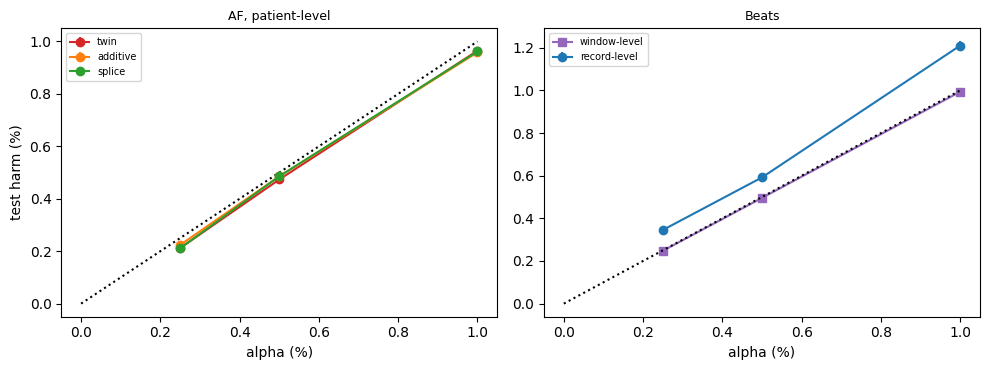

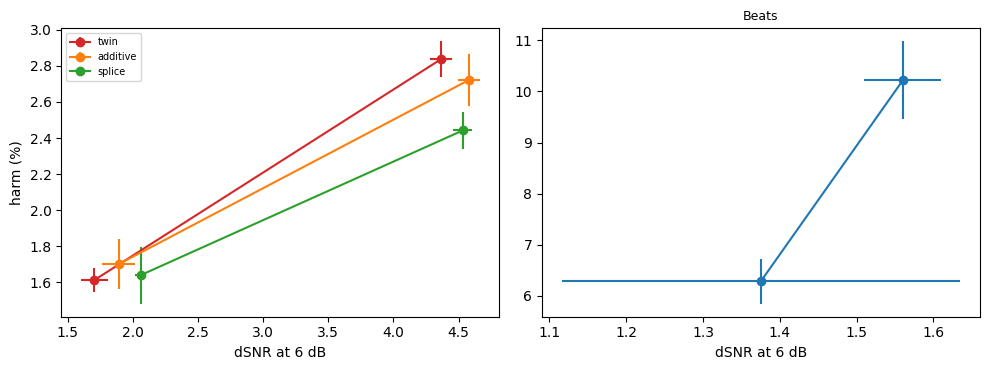

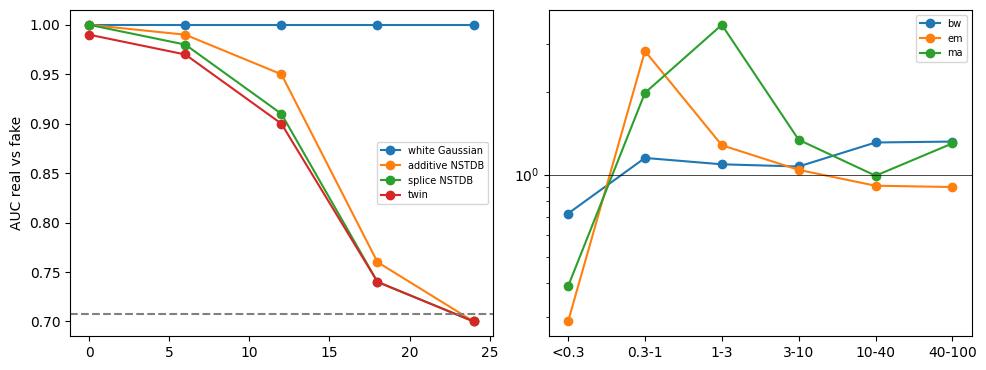

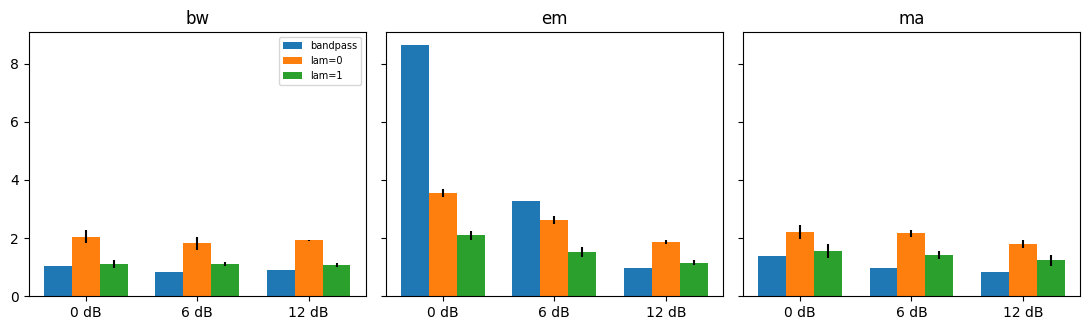

saved: ['FINAL_E1a_realism_best_case_TRANSCRIBED.csv', 'FINAL_E2_RQ1_kendall.csv', 'FINAL_E2b_architectures_mean.csv', 'FINAL_E2b_kendall_architectures.csv', 'FINAL_E3_domain_gap_TRANSCRIBED.csv', 'FINAL_E4_AF_consistency.csv', 'FINAL_E4_AF_paired_lambda.csv', 'FINAL_E4_beat_consistency.csv', 'FINAL_E4_beat_per_class.csv', 'FINAL_E4b_bandpass_vs_denoiser_pool.csv', 'FINAL_E5_AF_gate.csv', 'FINAL_E5_beat_gate.csv', 'FINAL_E5a_AF_gate_learned_vs_KL.csv', 'FINAL_E5b_AF_gate_real_only.csv', 'FINAL_E5c_gate_architectures.csv', 'FINAL_E7a_per_noise_type_lead_II.csv', 'FINAL_E7b_real_noise_flags.csv', 'FINAL_E7c_per_lead.csv', 'FINAL_E8_efficiency.csv', 'FINAL_ablation_e.csv', 'fig_gate_validity.png', 'fig_noise_type.png', 'fig_pareto.png', 'fig_twin.png']


In [20]:
rd = lambda n: pd.read_csv(f"{RES_DIR}/{n}.csv")
def agg(df, keys, cols):
    a = df.groupby(keys)[cols].agg(["mean", "std"]); a.columns = [f"{c}_{s}" for c, s in a.columns]
    return a.round(4).reset_index()
    
def show(name, df): df.to_csv(f"{RES_DIR}/FINAL_{name}.csv", index=False); print(f"\n=== {name} ===\n{df.to_string(index=False)}")
print(f"POOL: n={len(yc)} AF={int(yc.sum())} real noisy={int(real.sum())} raw acc={100*cr.mean():.2f}%")
fr, gr = rd("AF_free_all"), rd("AF_gate_all"); F8 = fr[fr.arch == "FCN-DAE"]
E4 = agg(F8, ["arm", "lam"], ["dSNR_0", "dSNR_6", "harm", "harm_real", "harm_syn", "rescue", "acc"]); show("E4_AF_consistency", E4)
pv = F8.pivot_table(index=["arm", "seed"], columns="lam", values=["harm", "harm_real", "dSNR_6"])
d = pd.DataFrame({"h": pv["harm"][1] - pv["harm"][0], "r": pv["harm_real"][1] - pv["harm_real"][0], "s": pv["dSNR_6"][1] - pv["dSNR_6"][0]}).reset_index()
show("E4_AF_paired_lambda", d.groupby("arm").agg(n=("h", "size"), harm_diff=("h", "mean"), harm_neg=("h", lambda v: int((v < 0).sum())), real_diff=("r", "mean"),
     real_nonpos=("r", lambda v: int((v <= 0.005).sum())), real_zero=("r", lambda v: int((v.abs() < 0.005).sum())), dSNR6_min=("s", "min"), dSNR6_max=("s", "max")).reset_index().round(2))
E5 = agg(gr[(gr.arch == "FCN-DAE") & (gr.lam == 1)], ["arm", "alpha"], ["harm", "harm_p95", "harm_real", "accept", "acc", "rescue", "viol"]); show("E5_AF_gate", E5)
show("E5c_gate_architectures", agg(gr[gr.lam == 0], ["arch", "alpha"], ["always_harm", "always_acc", "auc", "harm", "accept", "acc", "rescue", "harm_real", "viol"]))
show("E2b_architectures_mean", agg(rd("E2b_architectures_per_model").assign(arch=lambda x: x.arch), ["arch"], ["dSNR_0", "dSNR_6", "harm", "harm_real", "net", "acc"]))
for n in ["E2_RQ1_kendall", "E2b_kendall_architectures", "E5a_AF_gate_learned_vs_KL", "E5b_AF_gate_real_only", "E4b_bandpass_vs_denoiser_pool", "ablation_e_per_model"]:
    x = rd(n); show(n if n != "ablation_e_per_model" else "ablation_e", x.round(3) if n != "ablation_e_per_model" else agg(x, ["variant"], ["dSNR_0", "dSNR_6", "harm", "harm_real", "harm_syn", "rescue", "net", "acc"]))
bf, bg, bc, bw = rd("beat_per_seed_gatefree"), rd("beat_per_seed_gated"), rd("beat_per_class"), rd("beat_window_level")
show("E4_beat_consistency", agg(bf, ["lam"], ["dSNR_0", "dSNR_6", "harm", "rescue", "acc"])); show("E4_beat_per_class", agg(bc, ["lam", "cls"], ["harm", "rescue", "raw_recall"]))
Bg = agg(bg, ["alpha"], ["harm", "harm_p95", "accept", "acc", "rescue", "viol", "harm_auc"]); Bg = Bg.merge(bw, on="alpha", how="left"); show("E5_beat_gate", Bg)
for n in ["E7a_per_noise_type_lead_II", "E7b_real_noise_flags", "E7c_per_lead", "E8_efficiency"]: show(n, rd(n).round(2))

# ---- TRANSCRIBED from earlier outputs (twin frozen; not re-run) ----
SN = [0, 6, 12, 18, 24]; auc_curve = {"white Gaussian": [1.00]*5, "additive NSTDB": [1.00, .99, .95, .76, .70], "splice NSTDB": [1.00, .98, .91, .74, .70], "twin": [.99, .97, .90, .74, .70]}
BN = ["<0.3", "0.3-1", "1-3", "3-10", "10-40", "40-100"]; spec = {"bw": [.72, 1.15, 1.09, 1.07, 1.31, 1.32], "em": [.29, 2.83, 1.28, 1.04, .91, .90], "ma": [.39, 1.99, 3.53, 1.34, .99, 1.30]}
show("E1a_realism_best_case_TRANSCRIBED", pd.DataFrame([["clean control", .708, "0.670-0.741"], ["white Gaussian", .999, "0.996-1.000"], ["additive NSTDB", .700, "0.664-0.739"], ["splice NSTDB", .705, "0.678-0.737"], ["twin", .697, "0.657-0.732"]], columns=["method", "AUC", "95%CI"]))
show("E3_domain_gap_TRANSCRIBED", pd.DataFrame([["bandpass", .72, 1.21, 2.63], ["MIT-BIH-trained twin", 5.30, 4.62, 4.26], ["PTB-XL-trained twin", 2.41, 1.99, 2.13]], columns=["denoiser", "harm_real", "harm_syn6", "harm_syn0"]))

# ---- figures ----
col = {"twin": "C3", "additive": "C1", "splice": "C2"}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for arm in col: e = E5[E5.arm == arm]; ax[0].errorbar(100 * e.alpha, e.harm_mean, e.harm_std, marker="o", c=col[arm], label=arm)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("alpha (%)"); ax[0].set_ylabel("test harm (%)"); ax[0].set_title("AF, patient-level", fontsize=9); ax[0].legend(fontsize=7)
b = Bg[Bg.alpha <= 0.01]; ax[1].errorbar(100 * b.alpha, b.harm_mean, b.harm_std, marker="o", label="record-level"); ax[1].plot(100 * b.alpha, b.window_harm, marker="s", c="C4", label="window-level")
ax[1].plot([0, 1], [0, 1], "k:"); ax[1].set_xlabel("alpha (%)"); ax[1].set_title("Beats", fontsize=9); ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_gate_validity.png", dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for arm in col: e = E4[E4.arm == arm].sort_values("lam"); ax[0].errorbar(e.dSNR_6_mean, e.harm_mean, xerr=e.dSNR_6_std, yerr=e.harm_std, marker="o", c=col[arm], label=arm)
ax[0].set_xlabel("dSNR at 6 dB"); ax[0].set_ylabel("harm (%)"); ax[0].legend(fontsize=7); e = agg(bf, ["lam"], ["dSNR_6", "harm"])
ax[1].errorbar(e.dSNR_6_mean, e.harm_mean, xerr=e.dSNR_6_std, yerr=e.harm_std, marker="o"); ax[1].set_xlabel("dSNR at 6 dB"); ax[1].set_title("Beats", fontsize=9)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_pareto.png", dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k, v in auc_curve.items(): ax[0].plot(SN, v, marker="o", label=k)
ax[0].axhline(.708, ls="--", c="gray"); ax[0].set_ylabel("AUC real vs fake"); ax[0].legend(fontsize=7)
for k, v in spec.items(): ax[1].plot(BN, v, marker="o", label=k)
ax[1].axhline(1, c="k", lw=.5); ax[1].set_yscale("log"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_twin.png", dpi=200); plt.show()
t1 = rd("E7a_per_noise_type_lead_II"); fig, ax = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for a, tn in zip(ax, NT):
    d = t1[t1.noise == tn]; x = np.arange(len(d)); w = .25; a.bar(x - w, d.bp_harm, w, label="bandpass"); a.bar(x, d.harm_l0, w, yerr=d.harm_l0_sd, label="lam=0"); a.bar(x + w, d.harm_l1, w, yerr=d.harm_l1_sd, label="lam=1")
    a.set_xticks(x); a.set_xticklabels([f"{s} dB" for s in d.snr]); a.set_title(tn)
ax[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_noise_type.png", dpi=200); plt.show()
print("saved:", sorted(f for f in os.listdir(RES_DIR) if f.startswith(("FINAL_", "fig_"))))

In [21]:
import time
for f in ["beat_clf.pt", "den_beat_s0_lam1.pt", "den_twin_ptb_lam1.pt", "den_twin_ptb_s1_lam1.pt", "af_II.pt"]:
    print(f, time.ctime(os.path.getmtime(f"{MODELS}/{f}")))
print(AF_FREE[(AF_FREE.arch=="FCN-DAE")&(AF_FREE.arm=="twin")][["seed","lam","dSNR_0","dSNR_6","harm","harm_real","acc"]].round(2).to_string(index=False))

beat_clf.pt Fri Oct 30 08:29:16 2026
den_beat_s0_lam1.pt Fri Oct 30 11:22:53 2026
den_twin_ptb_lam1.pt Fri Oct 30 09:21:24 2026
den_twin_ptb_s1_lam1.pt Fri Oct 30 09:25:27 2026
af_II.pt Fri Oct 30 08:32:34 2026
 seed  lam  dSNR_0  dSNR_6  harm  harm_real   acc
    0    0    8.24    4.46  2.94       1.93 95.25
    0    1    6.40    1.53  1.67       1.14 96.41
    1    0    8.23    4.36  2.85       2.96 95.42
    1    1    6.65    1.74  1.65       0.91 96.41
    2    0    8.17    4.34  2.80       2.05 95.34
    2    1    6.53    1.74  1.51       0.80 96.68
    3    0    8.22    4.43  2.69       2.05 95.61
    3    1    6.62    1.76  1.65       0.91 96.60
    4    0    8.05    4.25  2.91       2.16 95.36
    4    1    6.58    1.76  1.59       0.57 96.46


In [22]:
m0 = den_s[("twin", 1, 1)]                      # seed 1 (typical); seed 0 is the outlier
Xd = denoise(m0, Xc); pdc = p_af(Xd); cd = (pdc > .5) == yc
g, _ = fit_gate(m0); Fc_ = feats(Xc, Xd, prc, pdc); S = {"learned": g.predict_proba(Fc_)[:, 1], "KL only": Fc_[:, 4]}
rows = [dict(score=k, **r) for k, s in S.items() for r in crc_eval(s, cd, cr, [0.0025, 0.005, 0.01, 0.02], AF_SPLITS, real)]
pd.DataFrame(rows).to_csv(f"{RES_DIR}/E5a_AF_gate_learned_vs_KL.csv", index=False)
rows = [dict(calibration=("real-only" if ro else "mixture"), **r) for ro in (False, True)
        for r in crc_eval(S["learned"], cd, cr, [0.005, 0.01, 0.02], AF_SPLITS, real, real_only_cal=ro, test_real=True)]
pd.DataFrame(rows).to_csv(f"{RES_DIR}/E5b_AF_gate_real_only.csv", index=False)
Xbp = sosfiltfilt(sos, zscore(Xc), axis=-1).astype(np.float32); cb = (p_af(Xbp) > .5) == yc
sets = {"all": np.ones(len(yc), bool), "real noisy": real, "synthetic": ~real}
pd.DataFrame([dict(set=n, raw_acc=100*cr[m].mean(), bp_acc=100*cb[m].mean(), bp_harm=100*(cr&~cb)[m].mean(), bp_rescue=100*(~cr&cb)[m].mean(),
    den_acc=100*cd[m].mean(), den_harm=100*(cr&~cd)[m].mean(), den_rescue=100*(~cr&cd)[m].mean()) for n, m in sets.items()]).round(2).to_csv(f"{RES_DIR}/E4b_bandpass_vs_denoiser_pool.csv", index=False)
for f in ["E5a_AF_gate_learned_vs_KL", "E5b_AF_gate_real_only", "E4b_bandpass_vs_denoiser_pool"]:
    print(f); print(pd.read_csv(f"{RES_DIR}/{f}.csv").round(3).to_string(index=False))

E5a_AF_gate_learned_vs_KL
  score  alpha  harm  harm_p95  accept    acc  harm_real  rescue  viol
learned  0.002 0.221     0.499  93.387 96.277      0.126   2.997 0.365
learned  0.005 0.489     0.881  95.661 96.756      0.226   3.744 0.440
learned  0.010 0.964     1.650  98.145 96.754      0.617   4.218 0.390
learned  0.020 1.581     1.979  99.932 96.483      0.913   4.564 0.040
KL only  0.002 0.206     0.490  83.510 93.417      0.064   0.123 0.375
KL only  0.005 0.463     0.929  88.936 93.385      0.399   0.348 0.335
KL only  0.010 0.948     1.484  93.217 93.350      0.805   0.799 0.385
KL only  0.020 1.624     2.011  99.742 96.223      0.912   4.347 0.055
E5b_AF_gate_real_only
calibration  alpha  harm  harm_p95  accept    acc  harm_real  rescue  viol
    mixture  0.005 0.226     0.472  97.302 96.534      0.226   0.665 0.040
    mixture  0.010 0.617     1.185  99.077 96.479      0.617   0.999 0.120
    mixture  0.020 0.913     1.540  99.990 96.414      0.913   1.231 0.000
  real-only  

twin lambda=1, all 5 seeds:
       dSNR_0  dSNR_6  harm  harm_real    acc
mean    6.56    1.71  1.61       0.86  96.51
std     0.10    0.10  0.07       0.21   0.12
twin lambda=1, without seed 0:
       dSNR_0  dSNR_6  harm  harm_real    acc
mean    6.60    1.75  1.60       0.80  96.54
std     0.05    0.01  0.06       0.16   0.13


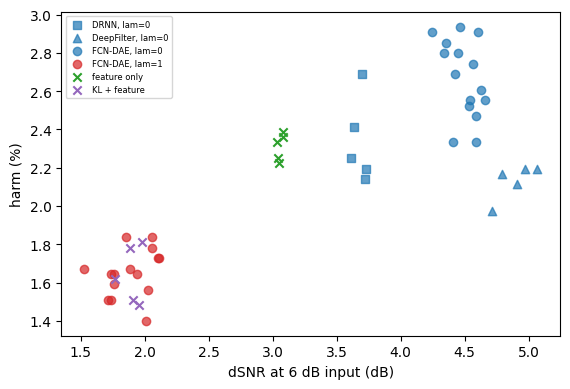

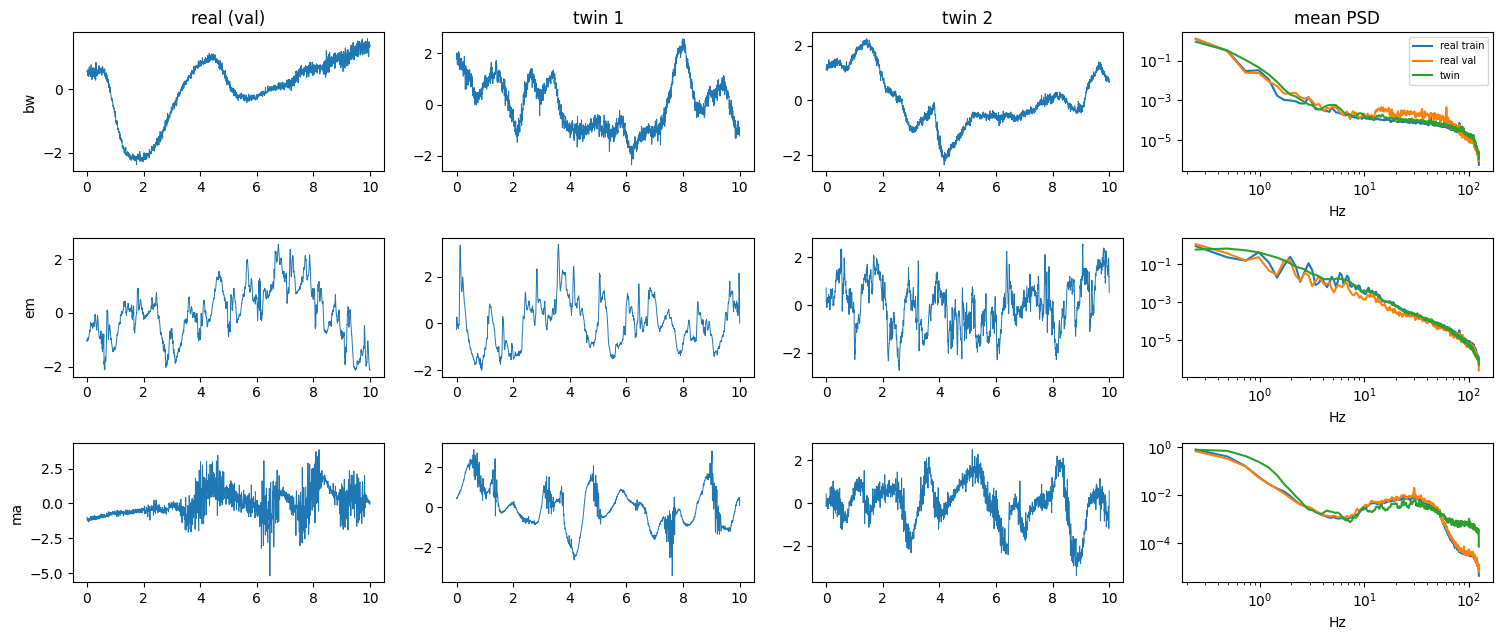

In [23]:
fr = pd.read_csv(f"{RES_DIR}/AF_free_all.csv"); ab = pd.read_csv(f"{RES_DIR}/ablation_e_per_model.csv")

# twin lambda=1 with and without the seed-0 outlier
t1_ = fr[(fr.arch == "FCN-DAE") & (fr.arm == "twin") & (fr.lam == 1)]
cols = ["dSNR_0", "dSNR_6", "harm", "harm_real", "acc"]
print("twin lambda=1, all 5 seeds:\n", t1_[cols].agg(["mean", "std"]).round(2))
print("twin lambda=1, without seed 0:\n", t1_[t1_.seed != 0][cols].agg(["mean", "std"]).round(2))

# Figure A: per-model scatter (every model one point)
fig, ax = plt.subplots(figsize=(5.8, 4)); mk = {"FCN-DAE": "o", "DRNN": "s", "DeepFilter": "^"}
for (arch, lam), d in fr.groupby(["arch", "lam"]):
    ax.scatter(d.dSNR_6, d.harm, marker=mk[arch], c="C3" if lam == 1 else "C0", alpha=.7, label=f"{arch}, lam={lam}")
for v, c in [("feature only", "C2"), ("KL + feature", "C4")]:
    d = ab[ab.variant == v]; ax.scatter(d.dSNR_6, d.harm, marker="x", c=c, label=v)
ax.set_xlabel("dSNR at 6 dB input (dB)"); ax.set_ylabel("harm (%)"); ax.legend(fontsize=6); plt.tight_layout()
plt.savefig(f"{RES_DIR}/fig_scatter.png", dpi=200); plt.show()

# Figure B: twin vs real noise, waveforms and spectra (real = val split, spectra also vs train)
gen_ = {n: gen_type(i, 72, seed=7 + i) for i, n in enumerate(NT)}
fig, ax = plt.subplots(3, 4, figsize=(15, 6.5)); t = np.arange(WLEN) / FS
for i, n in enumerate(NT):
    real_tr, real_va = Xn_tr[Tn_tr == i, 0], Xn_va[Tn_va == i, 0]
    ax[i, 0].plot(t, real_va[0], lw=.7); ax[i, 0].set_ylabel(n)
    ax[i, 1].plot(t, gen_[n][0], lw=.7); ax[i, 2].plot(t, gen_[n][1], lw=.7)
    for lab, x in [("real train", real_tr), ("real val", real_va), ("twin", gen_[n])]:
        f, P = welch(x, fs=FS, nperseg=1024, axis=-1); ax[i, 3].loglog(f[1:], P.mean(0)[1:], label=lab)
    ax[i, 3].set_xlabel("Hz")
ax[0, 0].set_title("real (val)"); ax[0, 1].set_title("twin 1"); ax[0, 2].set_title("twin 2"); ax[0, 3].set_title("mean PSD"); ax[0, 3].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/fig_twin_waveforms.png", dpi=200); plt.show()

In [24]:
from torch.utils.flop_counter import FlopCounterMode

DEN_REF = den_s[("twin", 1, 1)]                  # seed 1 (typical); seed 0 is the outlier

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
def flops(m, *inp):
    with torch.no_grad(), FlopCounterMode(display=False) as fc: m.eval()(*inp)
    return fc.get_total_flops() / 1e6
def timeit(fn, n=60, warm=10, cuda=False):
    for _ in range(warm): fn()
    if cuda: torch.cuda.synchronize()
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn()
        if cuda: torch.cuda.synchronize()
        ts.append(1000 * (time.perf_counter() - t0))
    return np.median(ts)

cpu = lambda m: copy.deepcopy(m).cpu().eval()
den_c, af_c, bclf_c, unet_c = cpu(DEN_REF), cpu(af_clf["II"]), cpu(beat_clf), cpu(twin_v)
x2500, x500, rr_, t1, c1 = torch.randn(1, 1, 2500), torch.randn(1, 1, 500), torch.randn(1, 5), torch.tensor([500]), torch.tensor([1])

def row(name, mc, mg, ac, ag, scale=1):
    r = dict(component=name, params_M=n_params(mc), MFLOPs=scale * flops(mc, *ac)); torch.set_num_threads(1)
    with torch.no_grad():
        r["cpu1_b1_ms"] = scale * timeit(lambda: mc(*ac))
        if torch.cuda.is_available(): r["gpu_b1_ms"] = scale * timeit(lambda: mg(*ag), cuda=True)
    return r
g_ = lambda *a: [t.to(device) for t in a]

rows = [row("AF denoiser FCN-DAE (2500)", den_c, DEN_REF, (x2500,), g_(x2500)),
        row("AF classifier CNN1D (2500)", af_c, af_clf["II"], (x2500,), g_(x2500)),
        row("beat denoiser FCN-DAE (500)", den_c, DEN_REF, (x500,), g_(x500)),
        row("beat classifier BeatNet (500+RR)", bclf_c, beat_clf, (x500, rr_), g_(x500, rr_)),
        row("twin U-Net, 1 pass (2500)", unet_c, twin_v, (x2500, t1, c1), g_(x2500, t1, c1))]
T = pd.DataFrame(rows); tw = T.iloc[-1].copy(); tw["component"] = "twin sampler, 100 DDIM steps (offline)"
for c in ["MFLOPs", "cpu1_b1_ms", "gpu_b1_ms"]:
    if c in tw and pd.notna(tw[c]): tw[c] = tw[c] * 100
T = pd.concat([T, tw.to_frame().T], ignore_index=True)

gate_k, _ = fit_gate(DEN_REF)                    # gate fitted for the same reference denoiser
def pipeline(x):
    xz = (x - x.mean()) / (x.std() + 1e-6); t = torch.from_numpy(xz[None, None].astype(np.float32))
    with torch.no_grad():
        xd = den_c(t); xdz = (xd - xd.mean()) / (xd.std() + 1e-6)
        pr = F.softmax(af_c(t), 1)[0, 1].item(); pdn = F.softmax(af_c(xdz), 1)[0, 1].item()
    a, b = np.clip(pr, 1e-6, 1 - 1e-6), np.clip(pdn, 1e-6, 1 - 1e-6)
    kl = a * np.log(a / b) + (1 - a) * np.log((1 - a) / (1 - b)); xd = xd.numpy()[0, 0]
    nd = np.log10(((xz - xd) ** 2).mean() / (xz ** 2).mean() + 1e-6); ob = 1 - sosfiltfilt(sos, xz).var() / xz.var()
    s = gate_k.predict_proba(np.array([[nd, ob, Hent(pr), Hent(pdn), kl, logit(pr), logit(pdn)]]))[0, 1]
    return pdn if s <= 0.5 else pr

xw = x2[0].astype(np.float32); torch.set_num_threads(1)
lat1 = timeit(lambda: pipeline(xw), n=40, warm=5)
T.to_csv(f"{RES_DIR}/E8_efficiency.csv", index=False)
print(T.round(3).to_string(index=False))
print(f"full gated AF pipeline per 10 s window, 1 CPU thread: {lat1:.1f} ms")
os.system("lscpu | grep 'Model name'")

                             component  params_M       MFLOPs cpu1_b1_ms  gpu_b1_ms
            AF denoiser FCN-DAE (2500)  0.284401   193.212864    4.67896   1.395142
            AF classifier CNN1D (2500)  0.090594    56.831872   1.325398   0.745928
           beat denoiser FCN-DAE (500)  0.284401    38.876864   1.621893   1.267765
      beat classifier BeatNet (500+RR)  0.091428    11.329472   0.647945   0.800702
             twin U-Net, 1 pass (2500)  2.686209  3915.404288  54.099029   6.276261
twin sampler, 100 DDIM steps (offline)  2.686209  391540.4288  5409.9029  627.62605
full gated AF pipeline per 10 s window, 1 CPU thread: 9.0 ms
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz


0

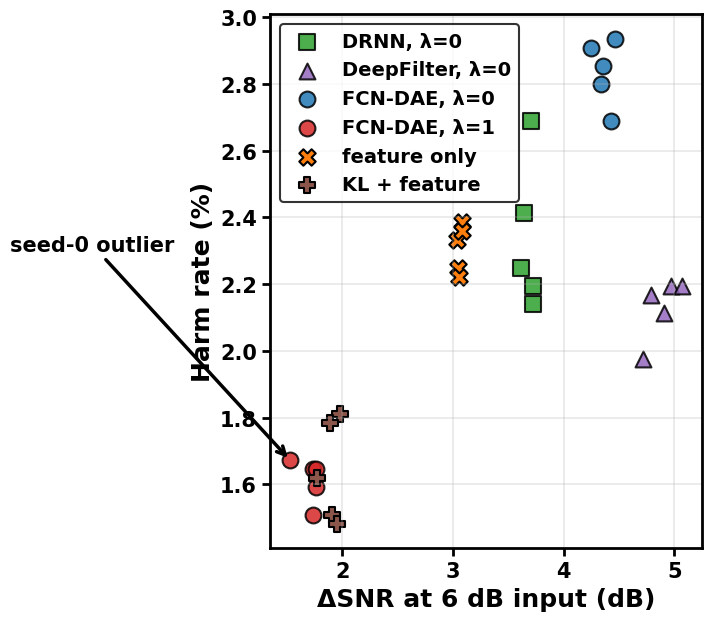

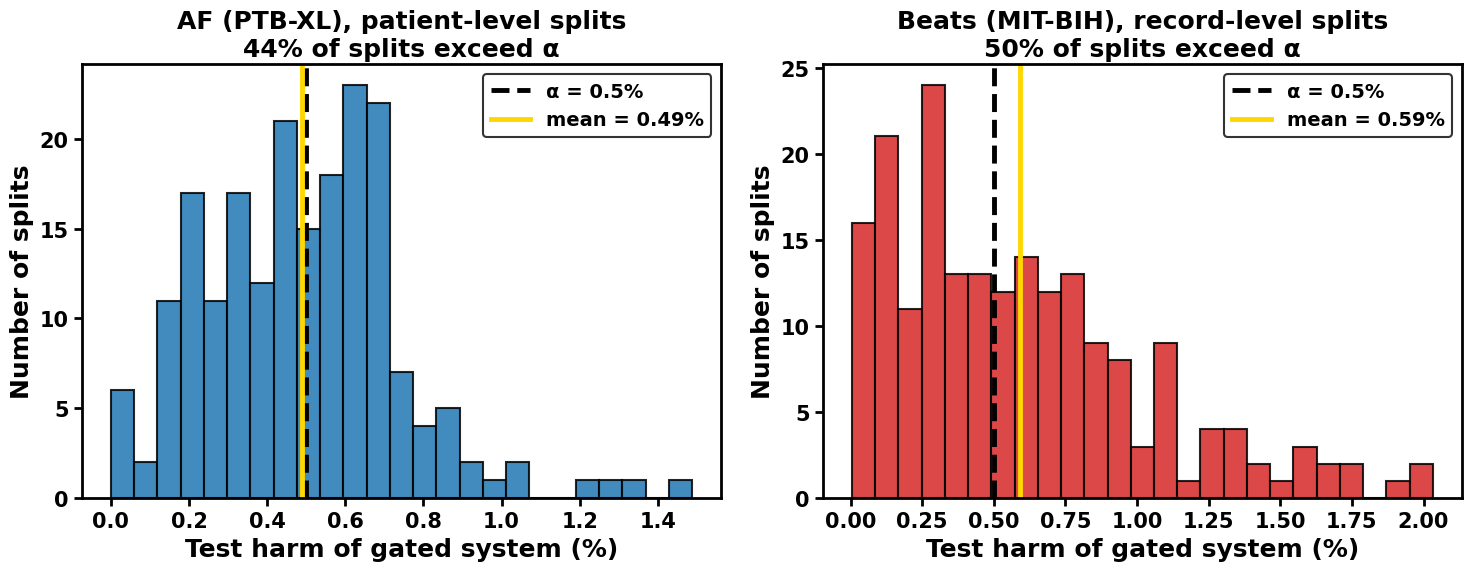

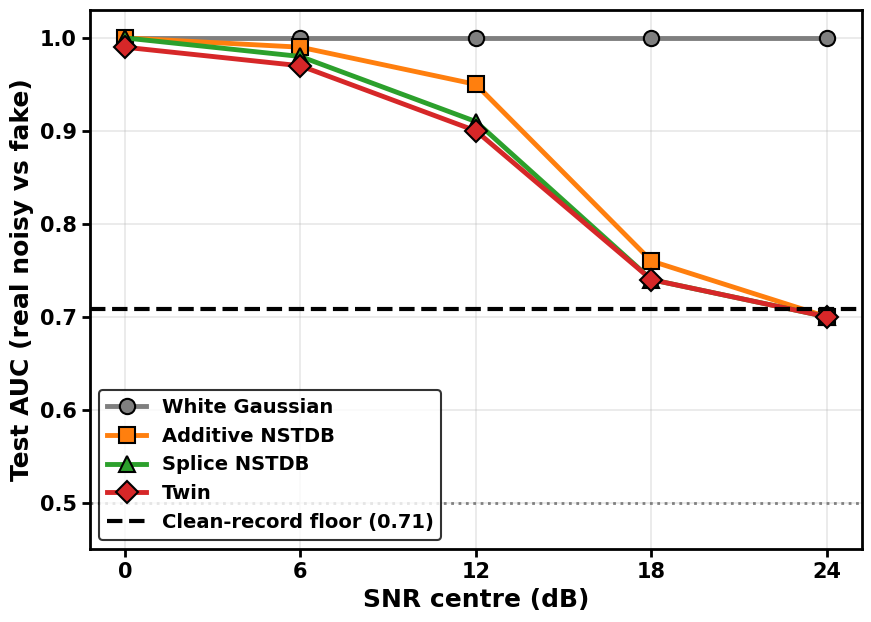

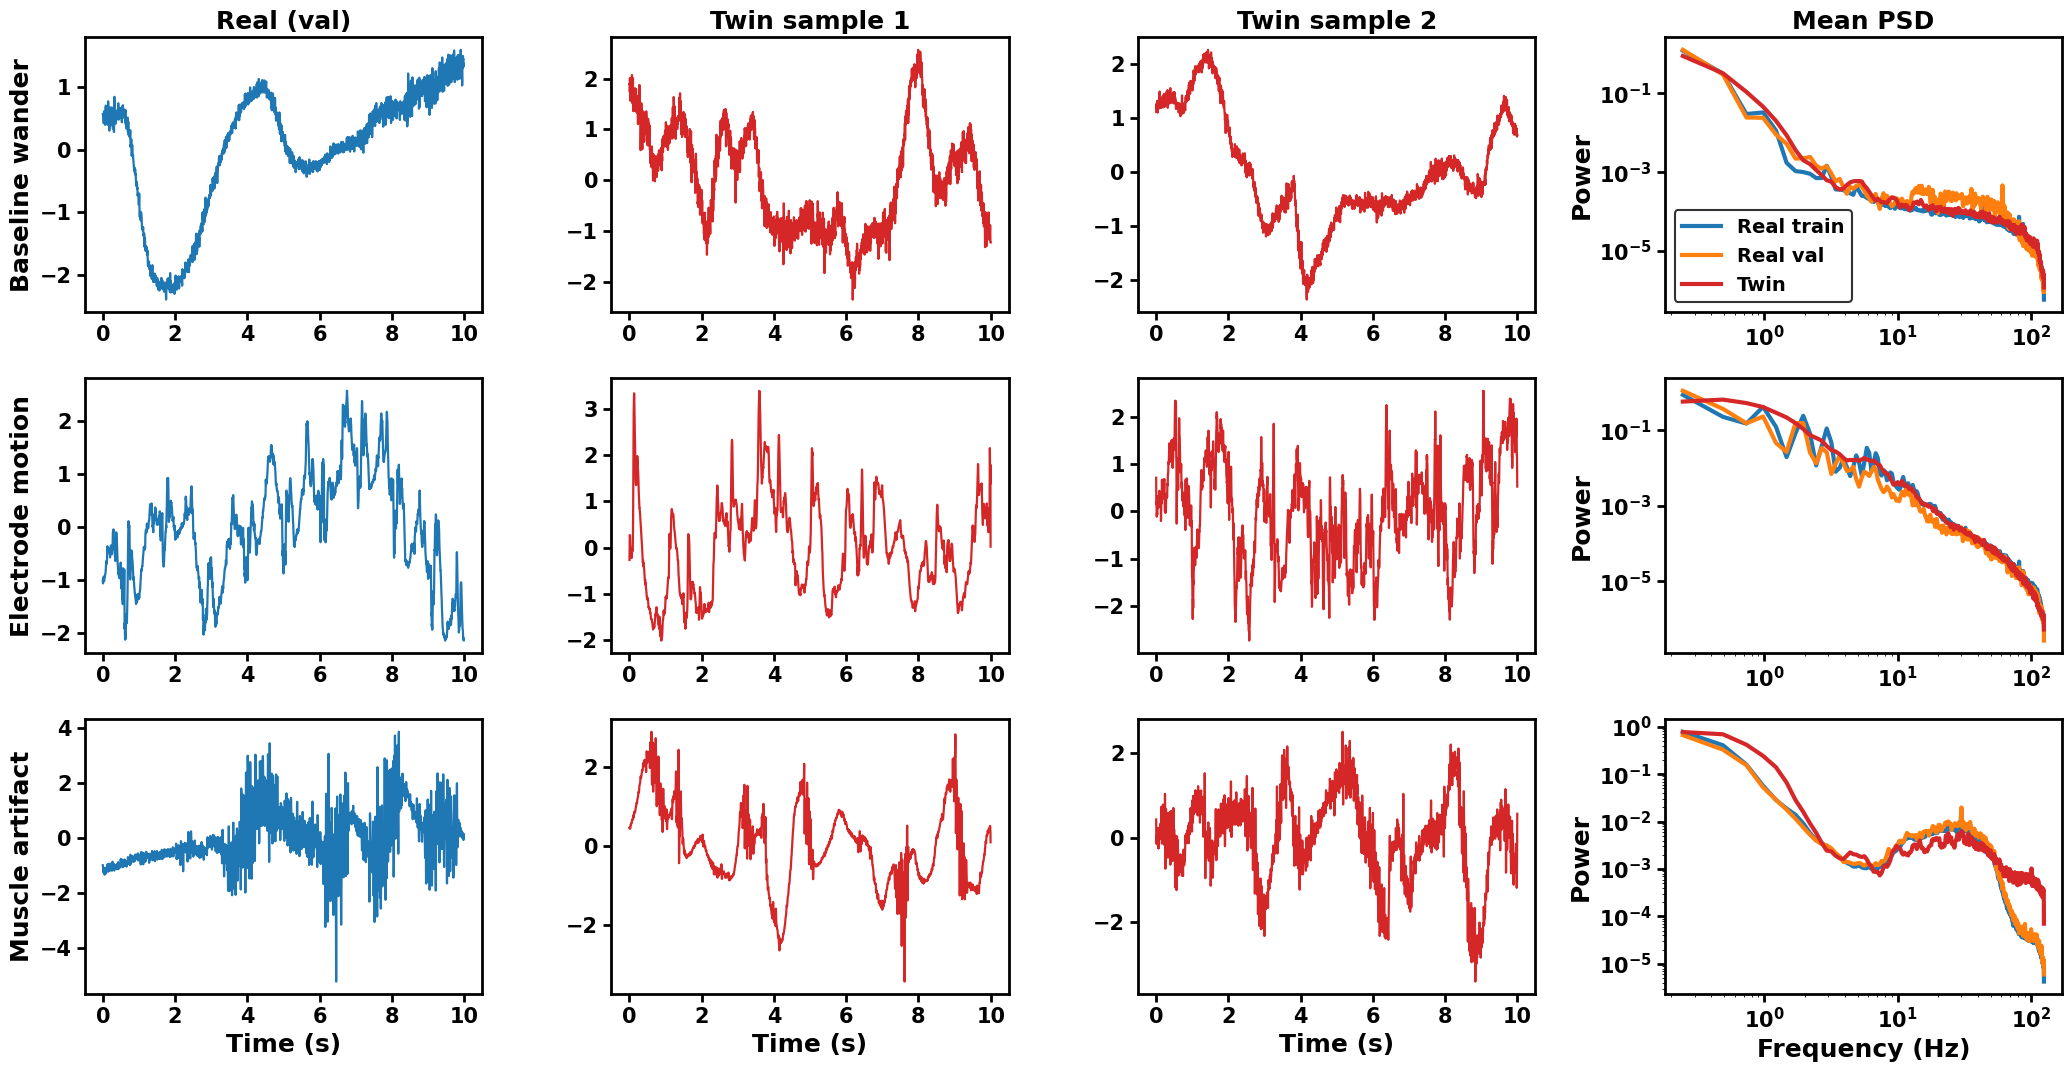

saved: ['FIG1_scatter.pdf', 'FIG1_scatter.png', 'FIG2_gate_per_split_hist.pdf', 'FIG2_gate_per_split_hist.png', 'FIG3_realism_auc.pdf', 'FIG3_realism_auc.png', 'FIG4_twin_waveforms_psd.pdf', 'FIG4_twin_waveforms_psd.png']


In [25]:
import matplotlib as mpl
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.weight": "bold", "font.size": 16,
    "axes.labelweight": "bold", "axes.labelsize": 18, "axes.titleweight": "bold", "axes.titlesize": 18,
    "axes.linewidth": 2.0, "xtick.labelsize": 15, "ytick.labelsize": 15,
    "xtick.major.width": 2.0, "ytick.major.width": 2.0, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.fontsize": 14, "legend.frameon": True, "legend.edgecolor": "black",
    "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "pdf.fonttype": 42})

def bold_ticks(ax):
    for l in ax.get_xticklabels() + ax.get_yticklabels(): l.set_fontweight("bold")
def bold_legend(ax, **kw):
    leg = ax.legend(prop={"weight": "bold", "size": 14}, **kw)
    if leg: leg.get_frame().set_linewidth(1.5)
    return leg
def save(fig, name):
    fig.savefig(f"{RES_DIR}/{name}.png"); fig.savefig(f"{RES_DIR}/{name}.pdf"); plt.show()

# =====================  FIG 1: per-model scatter (harm vs dSNR) =====================
fr = pd.read_csv(f"{RES_DIR}/AF_free_all.csv"); ab = pd.read_csv(f"{RES_DIR}/ablation_e_per_model.csv")
fr = fr[fr.arm == "twin"]                                   # same noise arm for all architectures
fig, ax = plt.subplots(figsize=(9, 6.5))
style = {("FCN-DAE", 0): ("o", "#1f77b4", "FCN-DAE, λ=0"), ("FCN-DAE", 1): ("o", "#d62728", "FCN-DAE, λ=1"),
         ("DRNN", 0): ("s", "#2ca02c", "DRNN, λ=0"), ("DeepFilter", 0): ("^", "#9467bd", "DeepFilter, λ=0")}
for (arch, lam), d in fr.groupby(["arch", "lam"]):
    m_, c_, lab = style[(arch, lam)]
    ax.scatter(d.dSNR_6, d.harm, marker=m_, c=c_, s=130, edgecolor="black", linewidth=1.5, alpha=.85, label=lab)
for v, c_, m_ in [("feature only", "#ff7f0e", "X"), ("KL + feature", "#8c564b", "P")]:
    d = ab[ab.variant == v]; ax.scatter(d.dSNR_6, d.harm, marker=m_, c=c_, s=140, edgecolor="black", linewidth=1.5, label=v)
o = fr[(fr.arch == "FCN-DAE") & (fr.lam == 1) & (fr.seed == 0)]
ax.annotate("seed-0 outlier", (o.dSNR_6.iloc[0], o.harm.iloc[0]), xytext=(-1.0, 2.3), fontsize=15, fontweight="bold",
            arrowprops=dict(arrowstyle="->", lw=2.5, color="black"))
ax.set_xlabel("ΔSNR at 6 dB input (dB)"); ax.set_ylabel("Harm rate (%)"); ax.grid(alpha=.3, lw=1.2)
bold_ticks(ax); bold_legend(ax, loc="upper left"); fig.tight_layout(); save(fig, "FIG1_scatter")

# =====================  FIG 2: per-split histogram of test harm =====================
A = 0.005
m_af = den_s[("twin", 1, 1)]
Xd = denoise(m_af, Xc); pdc = p_af(Xd); cd = (pdc > .5) == yc; h_af = cr & ~cd
g_af, _ = fit_gate(m_af); sc_af = g_af.predict_proba(feats(Xc, Xd, prc, pdc))[:, 1]
af_h = []
for mc, mt in AF_SPLITS:
    tau = crc_tau(sc_af[mc], h_af[mc].astype(int), A); af_h.append(100 * ((sc_af <= tau) & h_af)[mt].mean())
af_h = np.array(af_h)

m_b = beat_den[(4, 1)]
Fp, Pd = bfeats(m_b, BXP, BRP, BPP); cdb = Pd.argmax(1) == ByP; h_b = BcrP & ~cdb
Ft, Pdt = bfeats(m_b, BXT, BRT, BPT); ht = ((BPT.argmax(1) == ByT) & (Pdt.argmax(1) != ByT)).astype(int)
g_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Ft, ht); sc_b = g_b.predict_proba(Fp)[:, 1]
b_h = []
for mc, mt in BSPLITS:
    tau = crc_tau(sc_b[mc], h_b[mc].astype(int), A); b_h.append(100 * ((sc_b <= tau) & h_b)[mt].mean())
b_h = np.array(b_h)

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a_, v, ttl, col in [(ax[0], af_h, "AF (PTB-XL), patient-level splits", "#1f77b4"), (ax[1], b_h, "Beats (MIT-BIH), record-level splits", "#d62728")]:
    a_.hist(v, bins=25, color=col, edgecolor="black", linewidth=1.5, alpha=.85)
    a_.axvline(100 * A, color="black", lw=3.5, ls="--", label=f"α = {100*A:.1f}%")
    a_.axvline(v.mean(), color="gold", lw=3.5, label=f"mean = {v.mean():.2f}%")
    a_.set_title(f"{ttl}\n{100*np.mean(v > 100*A):.0f}% of splits exceed α")
    a_.set_xlabel("Test harm of gated system (%)"); a_.set_ylabel("Number of splits"); bold_ticks(a_); bold_legend(a_, loc="upper right")
fig.tight_layout(); save(fig, "FIG2_gate_per_split_hist")

# =====================  FIG 3: realism AUC vs SNR =====================
SN = [0, 6, 12, 18, 24]
auc_curve = {"White Gaussian": [1.00, 1.00, 1.00, 1.00, 1.00], "Additive NSTDB": [1.00, .99, .95, .76, .70],
             "Splice NSTDB": [1.00, .98, .91, .74, .70], "Twin": [.99, .97, .90, .74, .70]}
sty = {"White Gaussian": ("#7f7f7f", "o", "-"), "Additive NSTDB": ("#ff7f0e", "s", "-"), "Splice NSTDB": ("#2ca02c", "^", "-"), "Twin": ("#d62728", "D", "-")}
fig, ax = plt.subplots(figsize=(9, 6.5))
for k, v in auc_curve.items():
    c_, m_, l_ = sty[k]; ax.plot(SN, v, color=c_, marker=m_, ls=l_, lw=3.5, ms=11, markeredgecolor="black", markeredgewidth=1.5, label=k)
ax.axhline(.708, color="black", ls="--", lw=3, label="Clean-record floor (0.71)"); ax.axhline(.5, color="gray", lw=2, ls=":")
ax.set_xlabel("SNR centre (dB)"); ax.set_ylabel("Test AUC (real noisy vs fake)"); ax.set_xticks(SN); ax.set_ylim(.45, 1.03)
ax.grid(alpha=.3, lw=1.2); bold_ticks(ax); bold_legend(ax, loc="lower left"); fig.tight_layout(); save(fig, "FIG3_realism_auc")

# =====================  FIG 4: twin waveforms and PSD =====================
gen_ = {n: gen_type(i, 72, seed=7 + i) for i, n in enumerate(NT)}
names = {"bw": "Baseline wander", "em": "Electrode motion", "ma": "Muscle artifact"}
fig, ax = plt.subplots(3, 4, figsize=(21, 11)); t = np.arange(WLEN) / FS
for i, n in enumerate(NT):
    rtr, rva = Xn_tr[Tn_tr == i, 0], Xn_va[Tn_va == i, 0]
    for j, (sig, ttl) in enumerate([(rva[0], "Real (val)"), (gen_[n][0], "Twin sample 1"), (gen_[n][1], "Twin sample 2")]):
        ax[i, j].plot(t, sig, lw=1.6, color="#1f77b4" if j == 0 else "#d62728")
        if i == 0: ax[i, j].set_title(ttl)
        if i == 2: ax[i, j].set_xlabel("Time (s)")
    ax[i, 0].set_ylabel(names[n])
    for lab, x, c_ in [("Real train", rtr, "#1f77b4"), ("Real val", rva, "#ff7f0e"), ("Twin", gen_[n], "#d62728")]:
        f, P = welch(x, fs=FS, nperseg=1024, axis=-1); ax[i, 3].loglog(f[1:], P.mean(0)[1:], lw=3, color=c_, label=lab)
    if i == 0: ax[i, 3].set_title("Mean PSD"); bold_legend(ax[i, 3], loc="lower left")
    if i == 2: ax[i, 3].set_xlabel("Frequency (Hz)")
    ax[i, 3].set_ylabel("Power")
for a_ in ax.ravel(): bold_ticks(a_)
fig.tight_layout(); save(fig, "FIG4_twin_waveforms_psd")
print("saved:", sorted(f for f in os.listdir(RES_DIR) if f.startswith("FIG")))

real noisy windows: {'train': 2503, 'val': 421, 'test': 415}
clean (no noise)   0.71(0.67-0.74)
white Gaussian     1.00(1.00-1.00)  1.00(1.00-1.00)  1.00(1.00-1.00)  1.00(1.00-1.00)  1.00(1.00-1.00)
additive NSTDB     1.00(1.00-1.00)  0.99(0.99-1.00)  0.94(0.93-0.96)  0.79(0.76-0.82)  0.70(0.67-0.74)
splice NSTDB       1.00(0.99-1.00)  0.98(0.97-0.98)  0.91(0.89-0.93)  0.74(0.72-0.77)  0.72(0.69-0.75)
twin               0.98(0.98-0.99)  0.95(0.93-0.96)  0.85(0.83-0.88)  0.73(0.69-0.76)  0.69(0.66-0.73)

best case (lowest AUC over SNR):
  clean (no noise)   AUC 0.710  95% CI 0.674-0.744
  white Gaussian     AUC 0.999  95% CI 0.996-1.000
  additive NSTDB     AUC 0.700  95% CI 0.666-0.737
  splice NSTDB       AUC 0.717  95% CI 0.692-0.751
  twin               AUC 0.694  95% CI 0.656-0.730

auc_curve = {'white Gaussian': [np.float64(0.999), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)], 'additive NSTDB': [np.float64(0.998), np.float64(0.993), np.float64(0.942), np.flo

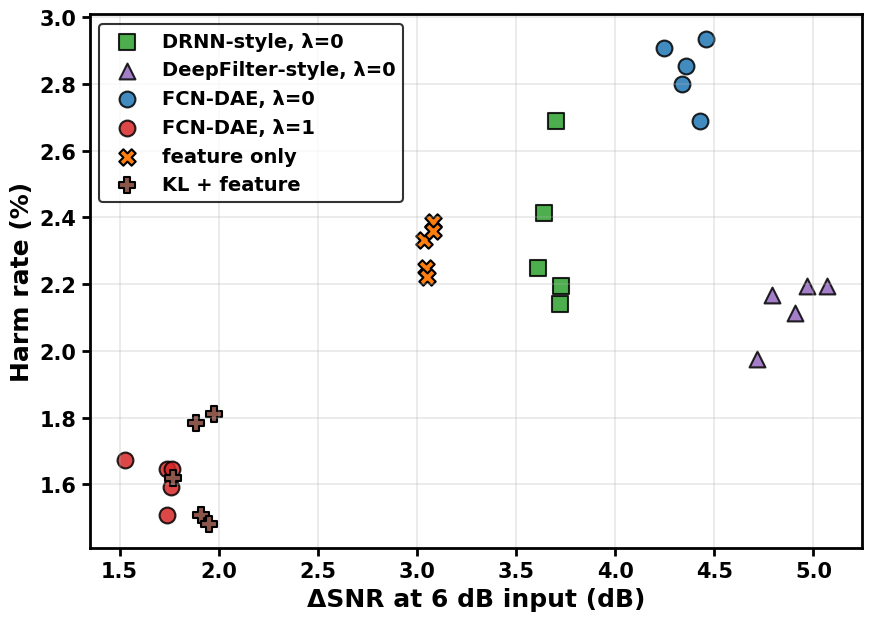


Fig 6 numbers: AF mean 0.49%, 44% of splits above alpha | beats mean 0.59%, 50% above


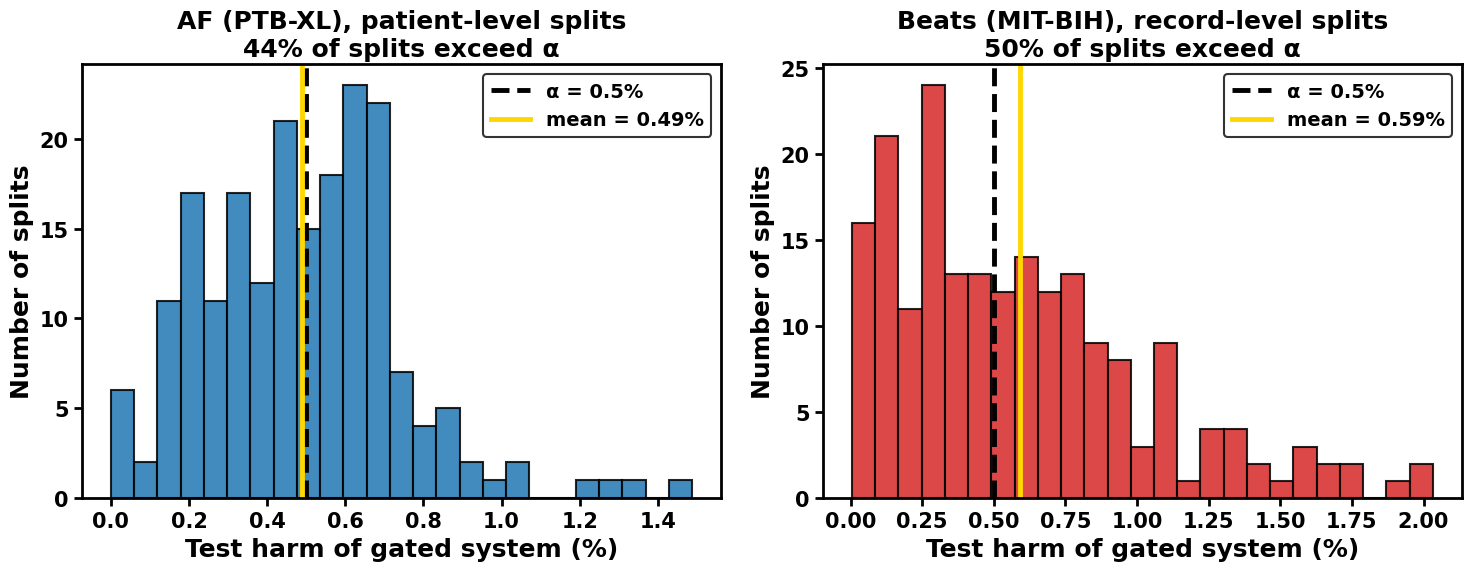

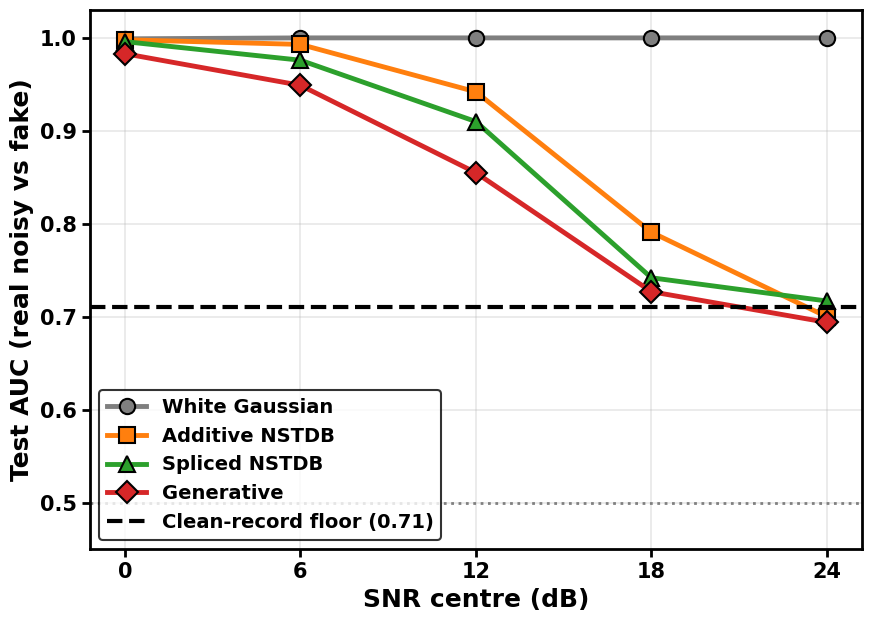

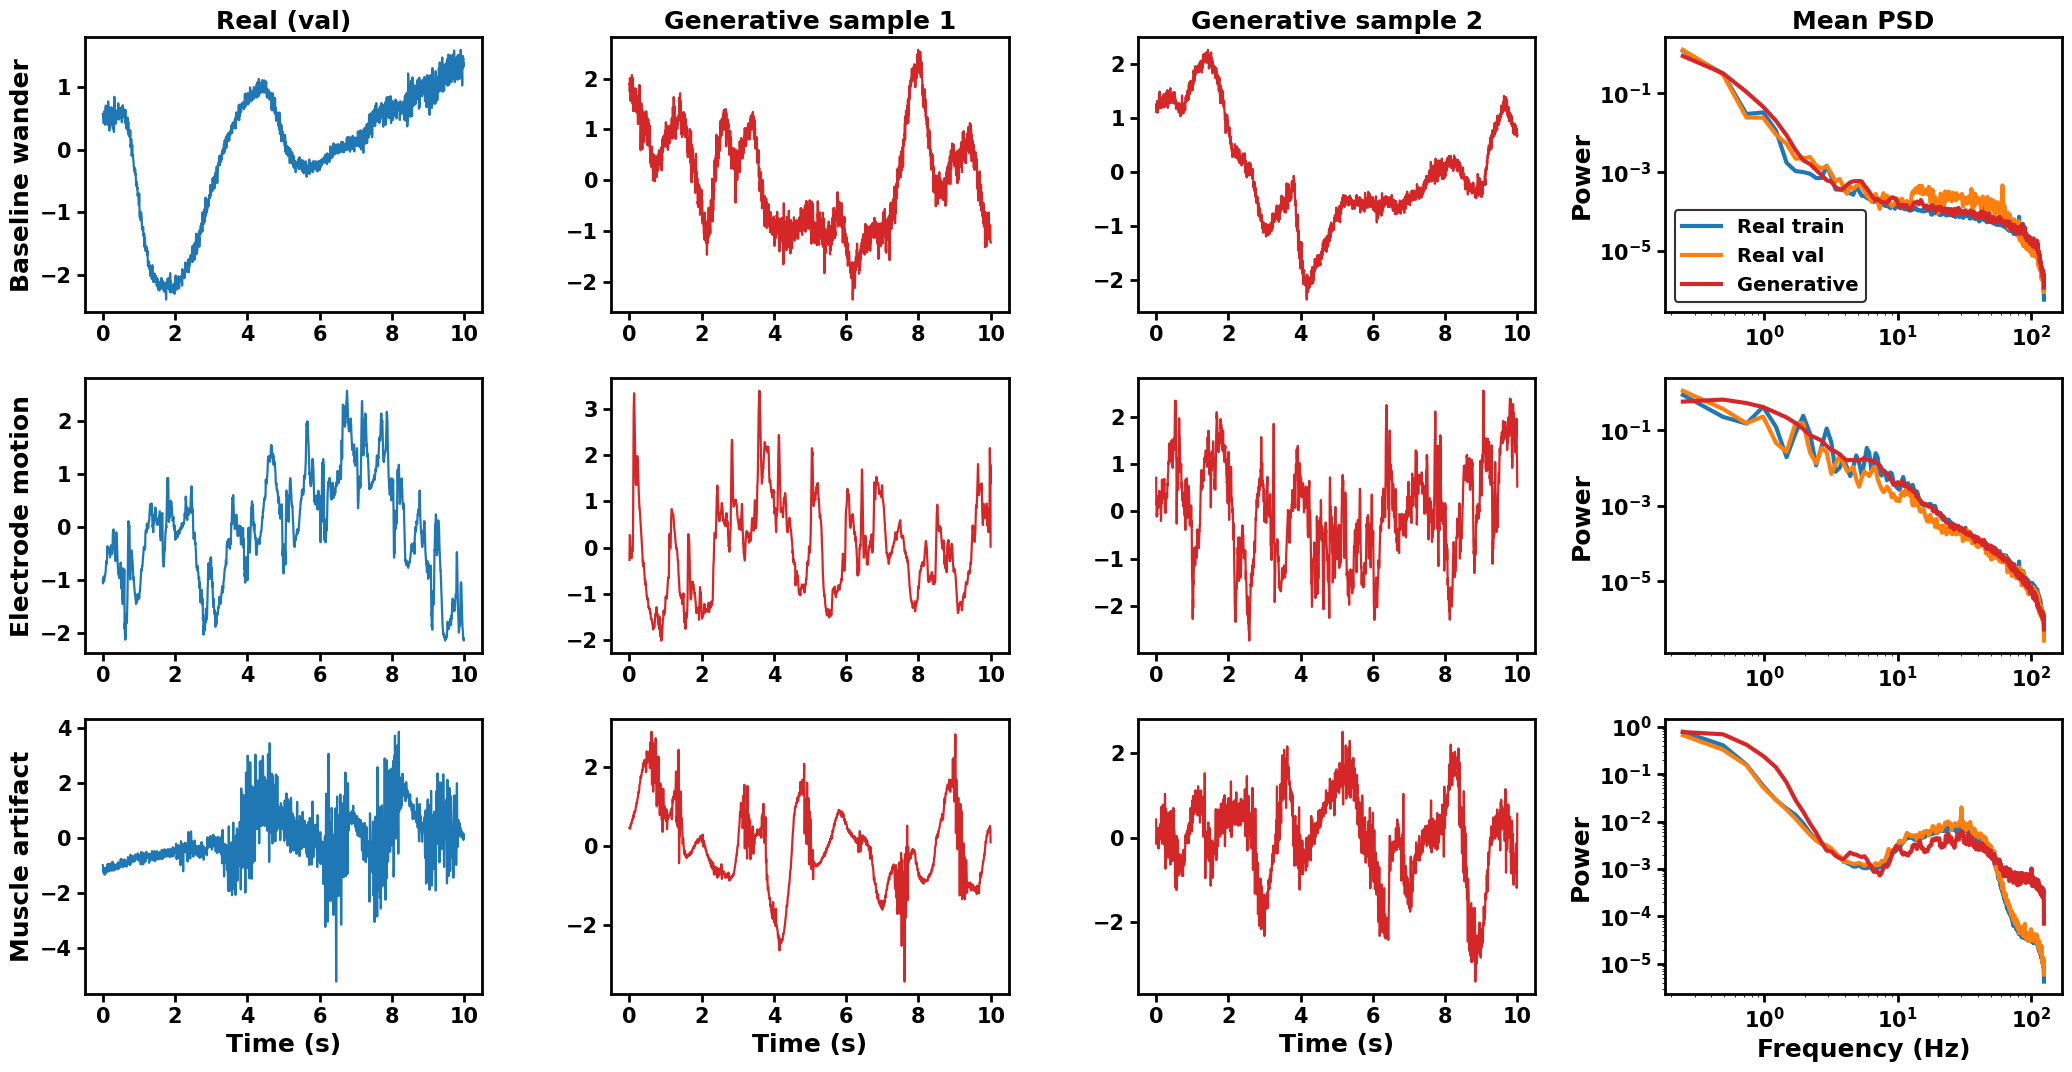

saved: ['FIG1_scatter.pdf', 'FIG1_scatter.png', 'FIG2_gate_per_split_hist.pdf', 'FIG2_gate_per_split_hist.png', 'FIG3_realism_auc.pdf', 'FIG3_realism_auc.png', 'FIG4_twin_waveforms_psd.pdf', 'FIG4_twin_waveforms_psd.png']


In [26]:
# ================= 1) REALISM TEST (recomputed on this run's frozen pools) =================
import contextlib, io
def noise_white(split, types, rng): return rng.standard_normal((len(types), WLEN))
REAL = {}
for s, m in SPL.items():
    r = x2[m & noisy & ok]
    REAL[s] = zscore(r - r.mean(1, keepdims=True)).astype(np.float32)
print("real noisy windows:", {s: len(v) for s, v in REAL.items()})          # expect train 2503, val 421, test 415

METHODS = {"clean (no noise)": None, "white Gaussian": noise_white, "additive NSTDB": noise_additive,
           "splice NSTDB": noise_splice, "twin": noise_twin}
def make_fake(method, split, n, snr_db, rng):
    x = x2[rng.choice(HOST[split], n, replace=False)].astype(np.float64); x -= x.mean(1, keepdims=True)
    fn = METHODS[method]
    if fn is None: return x
    z = fn(split, rng.integers(0, 3, n), rng); snr = snr_db + rng.uniform(-3, 3, n)
    return x + np.sqrt(x.var(1) / 10 ** (snr / 10))[:, None] * z
def two_sample_auc(method, snr_db, seed=0, epochs=8):
    rng = np.random.default_rng(seed); D = {}
    for s in ("train", "val", "test"):
        n = len(REAL[s]); fake = zscore(make_fake(method, s, n, snr_db, rng)).astype(np.float32)
        D[s] = (np.concatenate([REAL[s], fake])[:, None], np.r_[np.ones(n), np.zeros(n)].astype(np.int64))
    torch.manual_seed(seed)
    with contextlib.redirect_stdout(io.StringIO()):
        m = fit(CNN1D(2), D["train"][0], D["train"][1], D["val"][0], D["val"][1], auc_score, 2, epochs, ckpt=f"{MODELS}/tst.pt")
    P = predict_proba(m, D["test"][0])[:, 1]; y = D["test"][1]
    boot = [roc_auc_score(y[i], P[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(200))]
    return roc_auc_score(y, P), np.percentile(boot, 2.5), np.percentile(boot, 97.5)

SNRS = [0, 6, 12, 18, 24]; RES = {}
for name in METHODS:
    RES[name] = [two_sample_auc(name, None)] if METHODS[name] is None else [two_sample_auc(name, s) for s in SNRS]
    print(f"{name:18s}", "  ".join(f"{a:.2f}({lo:.2f}-{hi:.2f})" for a, lo, hi in RES[name]))
print("\nbest case (lowest AUC over SNR):")
for name, r in RES.items():
    a, lo, hi = min(r, key=lambda t: t[0]); print(f"  {name:18s} AUC {a:.3f}  95% CI {lo:.3f}-{hi:.3f}")
auc_curve = {k: [round(t[0], 3) for t in v] for k, v in RES.items() if METHODS[k] is not None}
print("\nauc_curve =", auc_curve)
pd.DataFrame([dict(method=k, snr=s, auc=a, lo=lo, hi=hi) for k, v in RES.items()
              for s, (a, lo, hi) in zip(SNRS if METHODS[k] else [None], v)]).to_csv(f"{RES_DIR}/E1a_realism_live.csv", index=False)

# ================= 2) GENERATOR FIDELITY NUMBERS FOR THE TEXT =================
print("\nbands (Hz):", BANDS2)
for ti, name in enumerate(NT):
    g = gen_type(ti, 216, seed=40 + ti); rtr, rva = Xn_tr[Tn_tr == ti, 0], Xn_va[Tn_va == ti, 0]
    tr_d = diffw(rtr)
    mg = max_xcorr(diffw(g[:72]), tr_d); mv = max_xcorr(diffw(rva[:72]), tr_d)
    print(f"{name}: ratio vs train {np.round(band_ratio2(g, rtr), 2)} | nonstat twin {nonstat(g).mean():.2f}, "
          f"real train {nonstat(rtr).mean():.2f}, real val {nonstat(rva).mean():.2f} | "
          f"median max corr to train: twin {np.median(mg):.2f}, real val {np.median(mv):.2f}")

# ================= 3) COUNTS THE TEXT NEEDS =================
ev = []
for s in SEEDS:
    for lam in (0, 1):
        cdm = (p_af(denoise(den_s[("twin", s, lam)], Xc)) > .5) == yc
        ev.append(dict(seed=s, lam=lam, harm_events_real=int((cr & ~cdm)[real].sum()),
                       rescue_events_real=int((~cr & cdm)[real].sum()), harm_events_all=int((cr & ~cdm).sum())))
print("\nevent counts (generative noise, FCN-DAE):"); print(pd.DataFrame(ev).to_string(index=False))
print("real-noisy pool windows:", int(real.sum()), "| AF among them:", int(yc[real].sum()), "| raw errors among them:", int((~cr)[real].sum()))

# ================= 4) FIGURES (re-exported with this run's numbers; "Generative" naming) =================
fr = pd.read_csv(f"{RES_DIR}/AF_free_all.csv"); ab = pd.read_csv(f"{RES_DIR}/ablation_e_per_model.csv"); fr = fr[fr.arm == "twin"]

# Fig 5: per-model scatter (no outlier annotation)
fig, ax = plt.subplots(figsize=(9, 6.5))
style = {("FCN-DAE", 0): ("o", "#1f77b4", "FCN-DAE, λ=0"), ("FCN-DAE", 1): ("o", "#d62728", "FCN-DAE, λ=1"),
         ("DRNN", 0): ("s", "#2ca02c", "DRNN-style, λ=0"), ("DeepFilter", 0): ("^", "#9467bd", "DeepFilter-style, λ=0")}
for (arch, lam), d in fr.groupby(["arch", "lam"]):
    m_, c_, lab = style[(arch, lam)]
    ax.scatter(d.dSNR_6, d.harm, marker=m_, c=c_, s=130, edgecolor="black", linewidth=1.5, alpha=.85, label=lab)
for v, c_, m_ in [("feature only", "#ff7f0e", "X"), ("KL + feature", "#8c564b", "P")]:
    d = ab[ab.variant == v]; ax.scatter(d.dSNR_6, d.harm, marker=m_, c=c_, s=140, edgecolor="black", linewidth=1.5, label=v)
ax.set_xlabel("ΔSNR at 6 dB input (dB)"); ax.set_ylabel("Harm rate (%)"); ax.grid(alpha=.3, lw=1.2)
bold_ticks(ax); bold_legend(ax, loc="upper left"); fig.tight_layout(); save(fig, "FIG1_scatter")

# Fig 6: per-split histograms (AF: generative noise, seed 1, lambda=1; beats: seed 4, lambda=1)
A = 0.005
m_af = den_s[("twin", 1, 1)]; Xd = denoise(m_af, Xc); pdc = p_af(Xd); cd = (pdc > .5) == yc; h_af = cr & ~cd
g_af, _ = fit_gate(m_af); sc_af = g_af.predict_proba(feats(Xc, Xd, prc, pdc))[:, 1]
af_h = np.array([100 * ((sc_af <= crc_tau(sc_af[mc], h_af[mc].astype(int), A)) & h_af)[mt].mean() for mc, mt in AF_SPLITS])
m_b = beat_den[(4, 1)]
Fp, Pd = bfeats(m_b, BXP, BRP, BPP); cdb = Pd.argmax(1) == ByP; h_b = BcrP & ~cdb
Ft, Pdt = bfeats(m_b, BXT, BRT, BPT); ht = ((BPT.argmax(1) == ByT) & (Pdt.argmax(1) != ByT)).astype(int)
g_b = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(Ft, ht); sc_b = g_b.predict_proba(Fp)[:, 1]
b_h = np.array([100 * ((sc_b <= crc_tau(sc_b[mc], h_b[mc].astype(int), A)) & h_b)[mt].mean() for mc, mt in BSPLITS])
print(f"\nFig 6 numbers: AF mean {af_h.mean():.2f}%, {100*np.mean(af_h > 100*A):.0f}% of splits above alpha | beats mean {b_h.mean():.2f}%, {100*np.mean(b_h > 100*A):.0f}% above")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a_, v, ttl, col in [(ax[0], af_h, "AF (PTB-XL), patient-level splits", "#1f77b4"), (ax[1], b_h, "Beats (MIT-BIH), record-level splits", "#d62728")]:
    a_.hist(v, bins=25, color=col, edgecolor="black", linewidth=1.5, alpha=.85)
    a_.axvline(100 * A, color="black", lw=3.5, ls="--", label=f"α = {100*A:.1f}%")
    a_.axvline(v.mean(), color="gold", lw=3.5, label=f"mean = {v.mean():.2f}%")
    a_.set_title(f"{ttl}\n{100*np.mean(v > 100*A):.0f}% of splits exceed α")
    a_.set_xlabel("Test harm of gated system (%)"); a_.set_ylabel("Number of splits"); bold_ticks(a_); bold_legend(a_, loc="upper right")
fig.tight_layout(); save(fig, "FIG2_gate_per_split_hist")

# Fig 3: realism curve from the LIVE results above
sty = {"white Gaussian": ("#7f7f7f", "o"), "additive NSTDB": ("#ff7f0e", "s"), "splice NSTDB": ("#2ca02c", "^"), "twin": ("#d62728", "D")}
lab_ = {"white Gaussian": "White Gaussian", "additive NSTDB": "Additive NSTDB", "splice NSTDB": "Spliced NSTDB", "twin": "Generative"}
floor = RES["clean (no noise)"][0][0]
fig, ax = plt.subplots(figsize=(9, 6.5))
for k, v in auc_curve.items():
    c_, m_ = sty[k]; ax.plot(SNRS, v, color=c_, marker=m_, lw=3.5, ms=11, markeredgecolor="black", markeredgewidth=1.5, label=lab_[k])
ax.axhline(floor, color="black", ls="--", lw=3, label=f"Clean-record floor ({floor:.2f})"); ax.axhline(.5, color="gray", lw=2, ls=":")
ax.set_xlabel("SNR centre (dB)"); ax.set_ylabel("Test AUC (real noisy vs fake)"); ax.set_xticks(SNRS); ax.set_ylim(.45, 1.03)
ax.grid(alpha=.3, lw=1.2); bold_ticks(ax); bold_legend(ax, loc="lower left"); fig.tight_layout(); save(fig, "FIG3_realism_auc")

# Fig 4: generator waveforms and PSD ("Generative" labels)
gen_ = {n: gen_type(i, 72, seed=7 + i) for i, n in enumerate(NT)}
names = {"bw": "Baseline wander", "em": "Electrode motion", "ma": "Muscle artifact"}
fig, ax = plt.subplots(3, 4, figsize=(21, 11)); t = np.arange(WLEN) / FS
for i, n in enumerate(NT):
    rtr, rva = Xn_tr[Tn_tr == i, 0], Xn_va[Tn_va == i, 0]
    for j, (sig, ttl) in enumerate([(rva[0], "Real (val)"), (gen_[n][0], "Generative sample 1"), (gen_[n][1], "Generative sample 2")]):
        ax[i, j].plot(t, sig, lw=1.6, color="#1f77b4" if j == 0 else "#d62728")
        if i == 0: ax[i, j].set_title(ttl)
        if i == 2: ax[i, j].set_xlabel("Time (s)")
    ax[i, 0].set_ylabel(names[n])
    for lab, x, c_ in [("Real train", rtr, "#1f77b4"), ("Real val", rva, "#ff7f0e"), ("Generative", gen_[n], "#d62728")]:
        f, P = welch(x, fs=FS, nperseg=1024, axis=-1); ax[i, 3].loglog(f[1:], P.mean(0)[1:], lw=3, color=c_, label=lab)
    if i == 0: ax[i, 3].set_title("Mean PSD"); bold_legend(ax[i, 3], loc="lower left")
    if i == 2: ax[i, 3].set_xlabel("Frequency (Hz)")
    ax[i, 3].set_ylabel("Power")
for a_ in ax.ravel(): bold_ticks(a_)
fig.tight_layout(); save(fig, "FIG4_twin_waveforms_psd")
print("saved:", sorted(f for f in os.listdir(RES_DIR) if f.startswith("FIG")))